# 1/ Tổng quan dữ liệu
## Người thực hiện: Trần Tấn Phát
## Mục tiêu:
### Xác định nguồn dữ liệu, biến mục tiêu, các giá trị đầu vào
### Số thuộc tính, số dòng và ý nghĩa của các đặc trưng
### Xác định, thống kê dữ liệu thiếu, dữ liệu trùng và đề xuất cách xử lý
### Phân loại nhóm Numerical và Categorical
### Phân tích biến mục tiêu và mức độ mất cân bằng
### Phân tích đơn biến, đa biến
### Nhận xét

### Khởi tạo thư viện

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

### Khởi tạo tập dữ liệu ban đầu
### Nguồn dữ liệu được lấy từ các mẫu báo cáo của Trung tâm kiểm soát và phòng ngừa dịch bệnh
### Link dữ liệu: https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators
### Link bài báo: https://www.cdc.gov/mmwr/volumes/66/wr/mm6643a2.htm

In [2]:
# Đường dẫn tới file dữ liệu, đổi lại cho đúng với vị trí file trên máy
duong_dan = "../../../DATA/raw/diabetes_012_health_indicators_BRFSS2015.csv"

train_df = pd.read_csv(duong_dan)
print("Tên các cột:", train_df.columns)
print("Số lượng cột:", train_df.shape[1])
print("Số lượng dòng:", train_df.shape[0])
print("Các giá trị của biến mục tiêu:", train_df['Diabetes_012'].unique())

Tên các cột: Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')
Số lượng cột: 22
Số lượng dòng: 253680
Các giá trị của biến mục tiêu: [0. 2. 1.]


### Nhận xét:
Tổng cộng có 22 cột, trong đó 21 cột là thuộc tính đầu vào và 1 cột là biến mục tiêu Diabetes_012.

Có 253680 dòng dữ liệu, tương ứng với 253680 người trả lời khảo sát. Mỗi dòng là một người, gồm 21 câu trả lời về sức khỏe và lối sống cùng 1 kết quả chẩn đoán tiểu đường.

Biến mục tiêu Diabetes_012 có 3 giá trị. Giá trị 0 là không mắc bệnh, giá trị 1 là tiền tiểu đường, giá trị 2 là đã mắc tiểu đường.

Dữ liệu này cùng nguồn với file diabetes.csv tải bằng script dulieugoc.py. Hai file có 21 cột đặc trưng giống hệt nhau, chỉ khác cách ghi biến mục tiêu. File diabetes.csv dùng Diabetes_binary với 2 lớp, trong đó lớp 1 là gộp của tiền tiểu đường và tiểu đường. Notebook này dùng file 3 lớp vì giữ được nhiều thông tin hơn.

### Ý nghĩa của các đặc trưng

In [34]:
bang_y_nghia = pd.DataFrame({
    'Biến': ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
             'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost',
             'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income'],
    'Ý nghĩa': [
        'Huyết áp cao',
        'Cholesterol cao',
        'Có kiểm tra cholesterol trong 5 năm qua',
        'Chỉ số khối cơ thể',
        'Đã hút ít nhất 100 điếu thuốc trong đời',
        'Từng bị đột quỵ',
        'Bệnh mạch vành hoặc nhồi máu cơ tim',
        'Có vận động thể chất trong 30 ngày qua, không tính công việc',
        'Ăn trái cây ít nhất 1 lần mỗi ngày',
        'Ăn rau ít nhất 1 lần mỗi ngày',
        'Uống rượu nhiều, nam hơn 14 ly và nữ hơn 7 ly mỗi tuần',
        'Có bảo hiểm hoặc dịch vụ chăm sóc sức khỏe',
        'Cần đi khám trong 12 tháng qua nhưng không đủ tiền',
        'Tự đánh giá sức khỏe tổng quát',
        'Số ngày sức khỏe tinh thần kém trong 30 ngày qua',
        'Số ngày sức khỏe thể chất kém trong 30 ngày qua',
        'Khó khăn nghiêm trọng khi đi bộ hoặc leo cầu thang',
        'Giới tính',
        'Nhóm tuổi',
        'Trình độ học vấn',
        'Thu nhập hộ gia đình mỗi năm, đơn vị USD'],
    'Giá trị': [
        '0 là không, 1 là có', '0 là không, 1 là có', '0 là không, 1 là có',
        'Số liên tục, từ 12 đến 98',
        '0 là không, 1 là có', '0 là không, 1 là có', '0 là không, 1 là có', '0 là không, 1 là có',
        '0 là không, 1 là có', '0 là không, 1 là có', '0 là không, 1 là có', '0 là không, 1 là có',
        '0 là không, 1 là có',
        '1 tuyệt vời, 2 rất tốt, 3 tốt, 4 trung bình, 5 kém',
        'Số nguyên từ 0 đến 30', 'Số nguyên từ 0 đến 30',
        '0 là không, 1 là có',
        '0 là nữ, 1 là nam',
        '13 nhóm. 1 là 18 đến 24 tuổi, mỗi nhóm cách nhau 5 tuổi, 13 là từ 80 tuổi trở lên',
        '1 chưa đi học, 2 lớp 1 đến 8, 3 lớp 9 đến 11, 4 tốt nghiệp lớp 12, 5 học đại học một phần, 6 tốt nghiệp đại học',
        '8 mức. 1 là dưới 10 nghìn, 2 dưới 15 nghìn, 3 dưới 20 nghìn, 4 dưới 25 nghìn, 5 dưới 35 nghìn, 6 dưới 50 nghìn, 7 dưới 75 nghìn, 8 từ 75 nghìn trở lên']
})
pd.set_option('display.max_colwidth', None)
display(bang_y_nghia)
# Lưu bảng ý nghĩa đặc trưng vào thư mục nhật ký thí nghiệm
import os

save_path = r"C:\Users\admin\OneDrive\Máy tính\BÀI TẬP HK3\MAY HOC\MAY_HOC_NHOM\Do_An_Cuoi_Ky\notebooks\02_EDA\Experiments\Logs\Experiment_01_Ý_Nghĩa_Đặc_Trưng"

# Tạo thư mục nếu chưa tồn tại
os.makedirs(save_path, exist_ok=True)

# Lưu DataFrame thành file Excel
bang_y_nghia.to_excel(
    os.path.join(save_path, "Bang_Y_Nghia_Dac_Trung.xlsx"),
    index=False
)

print("Đã lưu bảng ý nghĩa đặc trưng thành công!")

,Biến,Ý nghĩa,Giá trị
0,HighBP,Huyết áp cao,"0 là không, 1 là có"
1,HighChol,Cholesterol cao,"0 là không, 1 là có"
2,CholCheck,Có kiểm tra cholesterol trong 5 năm qua,"0 là không, 1 là có"
3,BMI,Chỉ số khối cơ thể,"Số liên tục, từ 12 đến 98"
4,Smoker,Đã hút ít nhất 100 điếu thuốc trong đời,"0 là không, 1 là có"
5,Stroke,Từng bị đột quỵ,"0 là không, 1 là có"
6,HeartDiseaseorAttack,Bệnh mạch vành hoặc nhồi máu cơ tim,"0 là không, 1 là có"
7,PhysActivity,"Có vận động thể chất trong 30 ngày qua, không tính công việc","0 là không, 1 là có"
8,Fruits,Ăn trái cây ít nhất 1 lần mỗi ngày,"0 là không, 1 là có"
9,Veggies,Ăn rau ít nhất 1 lần mỗi ngày,"0 là không, 1 là có"


Đã lưu bảng ý nghĩa đặc trưng thành công!


### Nhận xét:
Trong 21 đặc trưng có 14 biến chỉ nhận hai giá trị không hoặc có, 4 biến có thứ tự là GenHlth, Age, Education và Income, và 3 biến số là BMI, MentHlth và PhysHlth. Các biến đều được lưu dạng số thực nhưng ý nghĩa của chúng khác nhau, nên phải đọc bảng trên để hiểu từng con số.

Hai biến quan trọng cần để ý ngay từ đầu là HighBP và HighChol, vì đây là hai yếu tố sức khỏe có liên quan chặt với tiểu đường. Phần phân tích bên dưới sẽ kiểm tra điều này bằng số liệu.

### 2/ Dữ liệu thiếu

In [35]:
# Tổng số ô bị thiếu trong toàn bộ bảng
print("Tổng số giá trị thiếu:", train_df.isnull().sum().sum())

# Thống kê dữ liệu thiếu theo từng cột
missing_data = pd.DataFrame({
    'Số lượng thiếu': train_df.isnull().sum(),
    'Tỷ lệ thiếu (%)': train_df.isnull().mean() * 100
})
missing_data = missing_data.sort_values(by='Số lượng thiếu', ascending=False)
display(missing_data)

# Hiển thị những cột có dữ liệu thiếu
missing_data[missing_data['Số lượng thiếu'] > 0]
import os

# Đường dẫn thư mục lưu kết quả thí nghiệm 02
save_path = r"C:\Users\admin\OneDrive\Máy tính\BÀI TẬP HK3\MAY HOC\MAY_HOC_NHOM\Do_An_Cuoi_Ky\notebooks\02_EDA\Experiments\Logs\Experiment_02_MissingValue"

# Tạo thư mục nếu chưa tồn tại
os.makedirs(save_path, exist_ok=True)

# Lưu bảng thống kê dữ liệu thiếu
missing_data.to_excel(
    os.path.join(save_path, "Thong_Ke_Du_Lieu_Thieu.xlsx"),
    index=True
)

# Lưu riêng những cột có dữ liệu thiếu
missing_columns = missing_data[missing_data['Số lượng thiếu'] > 0]

missing_columns.to_excel(
    os.path.join(save_path, "Cac_Cot_Co_Du_Lieu_Thieu.xlsx"),
    index=True
)

print("Đã lưu kết quả thống kê dữ liệu thiếu thành công!")

Tổng số giá trị thiếu: 0


,Số lượng thiếu,Tỷ lệ thiếu (%)
Diabetes_012,0,0.0
HighBP,0,0.0
HighChol,0,0.0
CholCheck,0,0.0
BMI,0,0.0
Smoker,0,0.0
Stroke,0,0.0
HeartDiseaseorAttack,0,0.0
PhysActivity,0,0.0
Fruits,0,0.0


Đã lưu kết quả thống kê dữ liệu thiếu thành công!


### Nhận xét:
Kết quả kiểm tra cho thấy bộ dữ liệu không có giá trị thiếu ở bất kỳ cột nào. Vì vậy không cần xóa dòng hay điền giá trị thay thế.



### Dữ liệu trùng

In [37]:
target = 'Diabetes_012'
cac_cot_dac_trung = [c for c in train_df.columns if c != target]

# Số dòng trùng hoàn toàn ở cả 22 cột
so_dong_trung = train_df.duplicated().sum()
print("Số dòng trùng:", so_dong_trung)
print("Tỷ lệ dòng trùng (%):", round(so_dong_trung / len(train_df) * 100, 2))

# Các dòng trùng thuộc nhóm nào của biến mục tiêu
print("\nBiến mục tiêu trong các dòng trùng:")
print(train_df[train_df.duplicated()][target].value_counts())

# Tỷ lệ các lớp nếu bỏ hết dòng trùng
print("\nTỷ lệ các lớp (%) khi giữ nguyên dữ liệu:")
print((train_df[target].value_counts(normalize=True) * 100).round(2))
print("\nTỷ lệ các lớp (%) khi bỏ dòng trùng:")
print((train_df.drop_duplicates()[target].value_counts(normalize=True) * 100).round(2))

# Những tổ hợp câu trả lời giống nhau nhưng nhãn khác nhau
nhom = train_df.groupby(cac_cot_dac_trung)[target].nunique()
print("\nSố tổ hợp câu trả lời giống nhau nhưng nhãn khác nhau:", (nhom > 1).sum())
import os

# Đường dẫn thư mục lưu kết quả thí nghiệm 03
save_path = r"C:\Users\admin\OneDrive\Máy tính\BÀI TẬP HK3\MAY HOC\MAY_HOC_NHOM\Do_An_Cuoi_Ky\notebooks\02_EDA\Experiments\Logs\Experiment_03_Dữ_Liệu_Trùng"

# Tạo thư mục nếu chưa tồn tại
os.makedirs(save_path, exist_ok=True)

# 1. Lưu các dòng bị trùng hoàn toàn
dong_trung = train_df[train_df.duplicated()]
dong_trung.to_excel(
    os.path.join(save_path, "Cac_Dong_Du_Lieu_Trung.xlsx"),
    index=False
)

# 2. Lưu thống kê số lượng dòng trùng
thong_ke_trung = pd.DataFrame({
    'Chỉ số': [
        'Tổng số dòng dữ liệu',
        'Số dòng trùng hoàn toàn',
        'Tỷ lệ dòng trùng (%)',
        'Số tổ hợp câu trả lời giống nhau nhưng nhãn khác nhau'
    ],
    'Giá trị': [
        len(train_df),
        so_dong_trung,
        round(so_dong_trung / len(train_df) * 100, 2),
        (nhom > 1).sum()
    ]
})

thong_ke_trung.to_excel(
    os.path.join(save_path, "Thong_Ke_Du_Lieu_Trung.xlsx"),
    index=False
)

# 3. Lưu phân bố biến mục tiêu trong các dòng trùng
phan_bo_nhan_trung = (
    dong_trung[target]
    .value_counts()
    .rename_axis('Nhãn Diabetes_012')
    .reset_index(name='Số lượng')
)

phan_bo_nhan_trung.to_excel(
    os.path.join(save_path, "Phan_Bo_Nhan_Trong_Dong_Trung.xlsx"),
    index=False
)

# 4. Lưu tỷ lệ các lớp trước và sau khi loại bỏ dòng trùng
ty_le_giu = train_df[target].value_counts(normalize=True) * 100
ty_le_bo = train_df.drop_duplicates()[target].value_counts(normalize=True) * 100

so_sanh_ty_le = pd.DataFrame({
    'Nhãn Diabetes_012': sorted(train_df[target].unique()),
})

so_sanh_ty_le['Giữ nguyên dữ liệu (%)'] = (
    so_sanh_ty_le['Nhãn Diabetes_012'].map(ty_le_giu).fillna(0)
)

so_sanh_ty_le['Sau khi bỏ dòng trùng (%)'] = (
    so_sanh_ty_le['Nhãn Diabetes_012'].map(ty_le_bo).fillna(0)
)

so_sanh_ty_le.to_excel(
    os.path.join(save_path, "So_Sanh_Ty_Le_Cac_Lop.xlsx"),
    index=False
)

print("Đã lưu toàn bộ kết quả thí nghiệm 03 thành công!")

Số dòng trùng: 23899
Tỷ lệ dòng trùng (%): 9.42

Biến mục tiêu trong các dòng trùng:
Diabetes_012
0.0    23648
2.0      249
1.0        2
Name: count, dtype: int64

Tỷ lệ các lớp (%) khi giữ nguyên dữ liệu:
Diabetes_012
0.0    84.24
2.0    13.93
1.0     1.83
Name: proportion, dtype: float64

Tỷ lệ các lớp (%) khi bỏ dòng trùng:
Diabetes_012
0.0    82.71
2.0    15.27
1.0     2.01
Name: proportion, dtype: float64

Số tổ hợp câu trả lời giống nhau nhưng nhãn khác nhau: 1834
Đã lưu toàn bộ kết quả thí nghiệm 03 thành công!


### Nhận xét:
Bộ dữ liệu có 23899 dòng trùng, chiếm khoảng 9.42 phần trăm. Gần như toàn bộ dòng trùng là người không mắc bệnh, cụ thể 23648 dòng thuộc lớp 0, 249 dòng thuộc lớp 2 và chỉ 2 dòng thuộc lớp 1.

Điều này hợp lý vì đây là dữ liệu khảo sát, phần lớn cột chỉ có hai giá trị, nên nhiều người khỏe mạnh có thể trả lời giống hệt nhau mà không phải là một người bị ghi hai lần. Nếu xóa hết dòng trùng thì tỷ lệ lớp 0 giảm từ 84.24 xuống 82.71 phần trăm và lớp 2 tăng từ 13.93 lên 15.27 phần trăm, tức là ta vô tình làm thay đổi phân bố thật của dân số.

Ngoài ra có 1834 tổ hợp câu trả lời giống nhau nhưng nhãn lại khác nhau. Điều này cho biết 21 đặc trưng này không đủ để phân biệt hoàn toàn người mắc bệnh và người không mắc bệnh, nên mô hình khó đạt độ chính xác rất cao.

Quyết định ở bước tổng quan là giữ nguyên dữ liệu, không xóa dòng trùng. Khi chia dữ liệu huấn luyện và kiểm tra ở bước sau cần nhớ rằng một số dòng giống nhau có thể rơi vào cả hai tập, làm điểm đánh giá hơi cao hơn thực tế một chút.

### Phân loại Numerical và Categorical

In [38]:
train_df.info()

# Numerical Features
numerical_features = ['BMI', 'MentHlth', 'PhysHlth']

# Categorical Nominal Features
nominal_features = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker',
    'Stroke', 'HeartDiseaseorAttack', 'PhysActivity',
    'Fruits', 'Veggies', 'HvyAlcoholConsump',
    'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'
]

# Categorical Ordinal Features
ordinal_features = ['GenHlth', 'Age', 'Education', 'Income']

categorical_features = nominal_features + ordinal_features

print("Numerical:", len(numerical_features))
print("Categorical Nominal:", len(nominal_features))
print("Categorical Ordinal:", len(ordinal_features))
print("Tổng Features:", len(numerical_features) + len(nominal_features) + len(ordinal_features))
import os

# Đường dẫn lưu kết quả thí nghiệm 04
save_path = r"C:\Users\admin\OneDrive\Máy tính\BÀI TẬP HK3\MAY HOC\MAY_HOC_NHOM\Do_An_Cuoi_Ky\notebooks\02_EDA\Experiments\Logs\Experiment_04_Numerical&Categorical"

os.makedirs(save_path, exist_ok=True)

# 1. Tạo bảng phân loại đặc trưng
bang_phan_loai = pd.DataFrame({
    'Tên đặc trưng': numerical_features + nominal_features + ordinal_features,
    'Loại đặc trưng': (
        ['Numerical'] * len(numerical_features) +
        ['Categorical Nominal'] * len(nominal_features) +
        ['Categorical Ordinal'] * len(ordinal_features)
    )
})

# 2. Tạo bảng thống kê số lượng đặc trưng
bang_thong_ke = pd.DataFrame({
    'Loại đặc trưng': [
        'Numerical',
        'Categorical Nominal',
        'Categorical Ordinal',
        'Tổng Features'
    ],
    'Số lượng': [
        len(numerical_features),
        len(nominal_features),
        len(ordinal_features),
        len(numerical_features) + len(nominal_features) + len(ordinal_features)
    ]
})

# 3. Lưu kết quả vào Excel
with pd.ExcelWriter(
    os.path.join(save_path, "Phan_Loai_Dac_Trung.xlsx"),
    engine='openpyxl'
) as writer:

    bang_phan_loai.to_excel(
        writer,
        sheet_name='Phan loai dac trung',
        index=False
    )

    bang_thong_ke.to_excel(
        writer,
        sheet_name='Thong ke',
        index=False
    )

print("Đã lưu kết quả thí nghiệm 04 thành công!")

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

### Nhận xét:
Qua việc khảo sát và phân loại, 21 thuộc tính được chia thành 3 nhóm. Nhóm Numerical có 3 thuộc tính, nhóm Categorical Nominal có 14 thuộc tính và nhóm Categorical Ordinal có 4 thuộc tính.

Tất cả thuộc tính đều được lưu dưới dạng float64, nhưng kiểu lưu trữ không phản ánh đúng bản chất của biến. Vì vậy việc phân loại dựa vào ý nghĩa và cách mã hóa của từng đặc trưng. Kết quả này là cơ sở để chọn cách thống kê, vẽ biểu đồ và tiền xử lý phù hợp cho từng nhóm ở các bước sau.

### Phân tích biến mục tiêu Diabetes_012

,Số lượng,Tỷ lệ (%)
Diabetes_012,,
0.0,213703,84.24
1.0,4631,1.83
2.0,35346,13.93


Lớp 0 gấp lớp 1: 46.1 lần
Lớp 0 gấp lớp 2: 6.0 lần
Độ chính xác nếu đoán toàn bộ là lớp 0 (%): 84.24


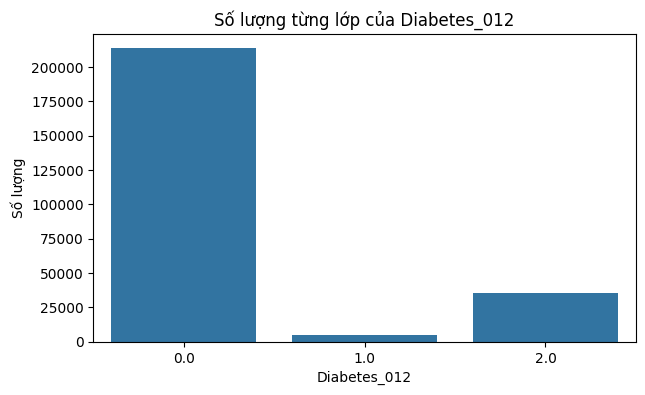

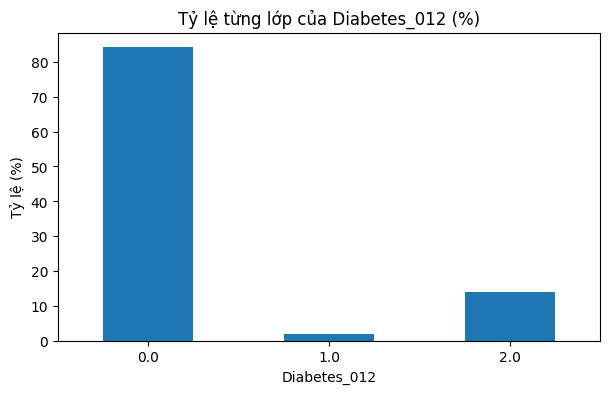

In [7]:
so_luong = train_df[target].value_counts().sort_index()
ty_le = train_df[target].value_counts(normalize=True).sort_index() * 100

bang_target = pd.DataFrame({'Số lượng': so_luong, 'Tỷ lệ (%)': ty_le.round(2)})
display(bang_target)

# Mức độ mất cân bằng: lớp lớn nhất chia cho từng lớp còn lại
print("Lớp 0 gấp lớp 1:", round(so_luong[0] / so_luong[1], 1), "lần")
print("Lớp 0 gấp lớp 2:", round(so_luong[0] / so_luong[2], 1), "lần")
print("Độ chính xác nếu đoán toàn bộ là lớp 0 (%):", round(ty_le[0], 2))

# Biểu đồ số lượng và tỷ lệ của từng lớp
plt.figure(figsize=(7, 4))
sns.countplot(data=train_df, x=target)
plt.title('Số lượng từng lớp của Diabetes_012')
plt.xlabel('Diabetes_012')
plt.ylabel('Số lượng')
plt.show()

plt.figure(figsize=(7, 4))
ty_le.plot(kind='bar')
plt.title('Tỷ lệ từng lớp của Diabetes_012 (%)')
plt.xlabel('Diabetes_012')
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.show()

### Nhận xét:
Biến mục tiêu bị mất cân bằng rất nặng. Lớp 0 có 213703 người, chiếm 84.24 phần trăm. Lớp 2 có 35346 người, chiếm 13.93 phần trăm. Lớp 1 chỉ có 4631 người, chiếm 1.83 phần trăm. Lớp 0 gấp khoảng 6 lần lớp 2 và gấp khoảng 46 lần lớp 1.

Hệ quả là một mô hình chỉ đoán mọi người đều không mắc bệnh cũng đã đúng 84.24 phần trăm. Vì vậy chỉ số accuracy sẽ gây hiểu lầm, khi đánh giá nên dùng thêm precision, recall và F1 cho từng lớp, đặc biệt là lớp 2.

Lớp 1 là lớp khó nhất vì quá ít mẫu và đặc điểm của nhóm này nằm giữa lớp 0 và lớp 2, điều này sẽ thấy rõ ở các biểu đồ phía dưới.

Một số hướng xử lý có thể dùng ở bước sau là đặt trọng số lớp bằng class_weight, lấy thêm mẫu cho lớp nhỏ bằng oversampling hoặc SMOTE, giảm mẫu lớp 0, hoặc đổi sang bài toán hai lớp bằng cách gộp lớp 1 vào lớp 0 hoặc lớp 2. Khi chia dữ liệu cần dùng stratify để các tập giữ cùng tỷ lệ lớp.

### Phân tích đơn biến và so sánh với biến mục tiêu
Mỗi biến có một cell riêng. Cell đưa ra thống kê của biến đó và hai biểu đồ so sánh biến với Diabetes_012, sau cell là phần nhận xét.

#### Nhóm biến số Numerical

Thống kê mô tả:
count    253680.00
mean         28.38
std           6.61
min          12.00
25%          24.00
50%          27.00
75%          31.00
max          98.00
Name: BMI, dtype: float64
Độ lệch (skew): 2.12
Cận dưới: 13.5 | Cận trên: 41.5
Số giá trị ngoại lai: 9847
Tỷ lệ giá trị bằng 0 (%): 0.0

Thống kê theo Diabetes_012:
               count   mean  median   std   min   max
Diabetes_012                                         
0.0           213703  27.74    27.0  6.26  12.0  98.0
1.0             4631  30.72    30.0  6.96  13.0  96.0
2.0            35346  31.94    31.0  7.36  13.0  98.0


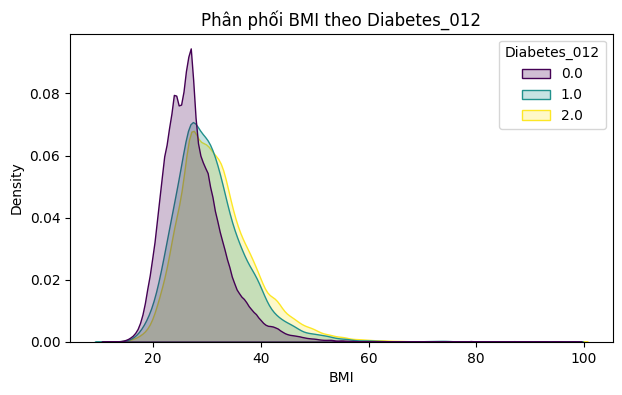

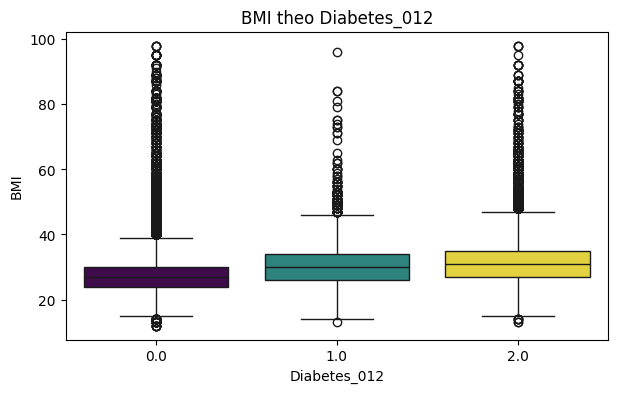

In [8]:
# Biến BMI: Chỉ số khối cơ thể
col = 'BMI'

# 1. Thống kê của biến
print("Thống kê mô tả:")
print(train_df[col].describe().round(2))
print("Độ lệch (skew):", round(train_df[col].skew(), 2))

# Đếm ngoại lai theo quy tắc IQR
q1 = train_df[col].quantile(0.25)
q3 = train_df[col].quantile(0.75)
iqr = q3 - q1
can_duoi = q1 - 1.5 * iqr
can_tren = q3 + 1.5 * iqr
so_ngoai_lai = ((train_df[col] < can_duoi) | (train_df[col] > can_tren)).sum()
print("Cận dưới:", can_duoi, "| Cận trên:", can_tren)
print("Số giá trị ngoại lai:", so_ngoai_lai)
print("Tỷ lệ giá trị bằng 0 (%):", round((train_df[col] == 0).mean() * 100, 1))

# 2. Thống kê của biến theo từng lớp của biến mục tiêu
print("\nThống kê theo Diabetes_012:")
print(train_df.groupby(target)[col].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
plt.figure(figsize=(7, 4))
sns.kdeplot(data=train_df, x=col, hue=target, common_norm=False, fill=True, palette='viridis')
plt.title('Phân phối BMI theo Diabetes_012')
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=train_df, x=target, y=col, hue=target, palette='viridis', legend=False)
plt.title('BMI theo Diabetes_012')
plt.show()

### Nhận xét BMI:
BMI có trung bình 28.38 và trung vị 27, nghĩa là người trong khảo sát phần lớn đã ở mức thừa cân. Giá trị nhỏ nhất là 12 và lớn nhất là 98. Độ lệch là 2.12, phân phối lệch phải do một số ít người có BMI rất cao.

Theo quy tắc IQR, ngưỡng trên là 41.5 và ngưỡng dưới là 13.5. Có tổng cộng 9847 giá trị nằm ngoài hai ngưỡng này, trong đó 9820 người vượt ngưỡng trên. Những giá trị rất cao như từ 80 trở lên chỉ có 281 người, nên có thể là ghi nhận bất thường. Tuy vậy những người này vẫn là câu trả lời có thể xảy ra trong khảo sát, nên ở bước tổng quan chưa xóa.

So với biến mục tiêu thì BMI tăng theo mức độ bệnh. Trung bình là 27.74 ở lớp 0, 30.72 ở lớp 1 và 31.94 ở lớp 2. Người mắc bệnh thường có BMI cao hơn khoảng 4 đơn vị so với người không mắc bệnh. Đây là một trong những biến số liên quan rõ nhất với tiểu đường.

Thống kê mô tả:
count    253680.00
mean          3.18
std           7.41
min           0.00
25%           0.00
50%           0.00
75%           2.00
max          30.00
Name: MentHlth, dtype: float64
Độ lệch (skew): 2.72
Cận dưới: -3.0 | Cận trên: 5.0
Số giá trị ngoại lai: 36208
Tỷ lệ giá trị bằng 0 (%): 69.3

Thống kê theo Diabetes_012:
               count  mean  median   std  min   max
Diabetes_012                                       
0.0           213703  2.94     0.0  7.06  0.0  30.0
1.0             4631  4.53     0.0  8.90  0.0  30.0
2.0            35346  4.46     0.0  8.95  0.0  30.0


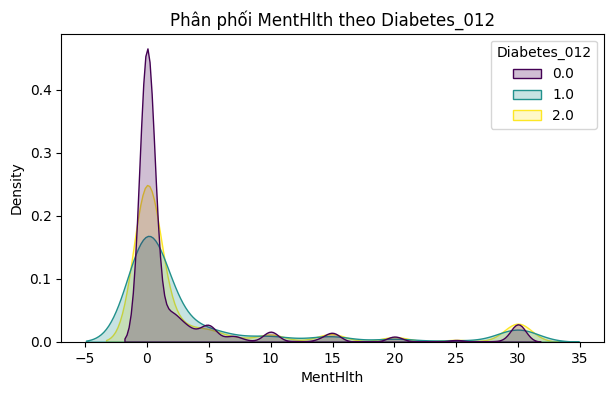

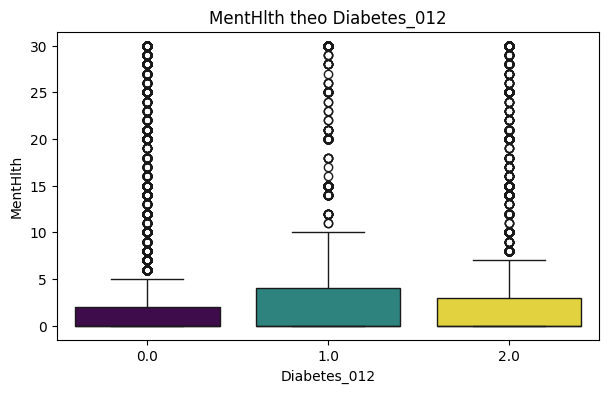

In [9]:
# Biến MentHlth: Số ngày sức khỏe tinh thần kém trong 30 ngày
col = 'MentHlth'

# 1. Thống kê của biến
print("Thống kê mô tả:")
print(train_df[col].describe().round(2))
print("Độ lệch (skew):", round(train_df[col].skew(), 2))

# Đếm ngoại lai theo quy tắc IQR
q1 = train_df[col].quantile(0.25)
q3 = train_df[col].quantile(0.75)
iqr = q3 - q1
can_duoi = q1 - 1.5 * iqr
can_tren = q3 + 1.5 * iqr
so_ngoai_lai = ((train_df[col] < can_duoi) | (train_df[col] > can_tren)).sum()
print("Cận dưới:", can_duoi, "| Cận trên:", can_tren)
print("Số giá trị ngoại lai:", so_ngoai_lai)
print("Tỷ lệ giá trị bằng 0 (%):", round((train_df[col] == 0).mean() * 100, 1))

# 2. Thống kê của biến theo từng lớp của biến mục tiêu
print("\nThống kê theo Diabetes_012:")
print(train_df.groupby(target)[col].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
plt.figure(figsize=(7, 4))
sns.kdeplot(data=train_df, x=col, hue=target, common_norm=False, fill=True, palette='viridis')
plt.title('Phân phối MentHlth theo Diabetes_012')
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=train_df, x=target, y=col, hue=target, palette='viridis', legend=False)
plt.title('MentHlth theo Diabetes_012')
plt.show()

### Nhận xét MentHlth:
MentHlth là số ngày sức khỏe tinh thần kém trong 30 ngày. Có 69.3 phần trăm người trả lời 0 ngày, nên trung vị là 0 và trung bình chỉ 3.18. Cũng có khoảng 4.8 phần trăm người trả lời đủ 30 ngày. Phân phối lệch phải mạnh với độ lệch 2.72 và dồn về hai đầu.

Quy tắc IQR đánh dấu rất nhiều ngoại lai vì Q3 chỉ bằng 2, nhưng các giá trị này đều nằm trong khoảng hợp lệ từ 0 đến 30 và phản ánh người thật sự có nhiều ngày tinh thần kém, nên không nên xóa. Có thể xử lý bằng cách chia nhóm, ví dụ 0 ngày, từ 1 đến 29 ngày và đủ 30 ngày, hoặc biến đổi log nếu dùng mô hình tuyến tính.

So với biến mục tiêu, trung bình là 2.94 ở lớp 0, 4.53 ở lớp 1 và 4.46 ở lớp 2. Có chênh lệch nhưng nhỏ, trung vị cả ba lớp đều bằng 0. Biến này liên quan yếu với tiểu đường.

Thống kê mô tả:
count    253680.00
mean          4.24
std           8.72
min           0.00
25%           0.00
50%           0.00
75%           3.00
max          30.00
Name: PhysHlth, dtype: float64
Độ lệch (skew): 2.21
Cận dưới: -4.5 | Cận trên: 7.5
Số giá trị ngoại lai: 40949
Tỷ lệ giá trị bằng 0 (%): 63.1

Thống kê theo Diabetes_012:
               count  mean  median   std  min   max
Diabetes_012                                       
0.0           213703  3.58     0.0   8.0  0.0  30.0
1.0             4631  6.35     0.0  10.3  0.0  30.0
2.0            35346  7.95     1.0  11.3  0.0  30.0


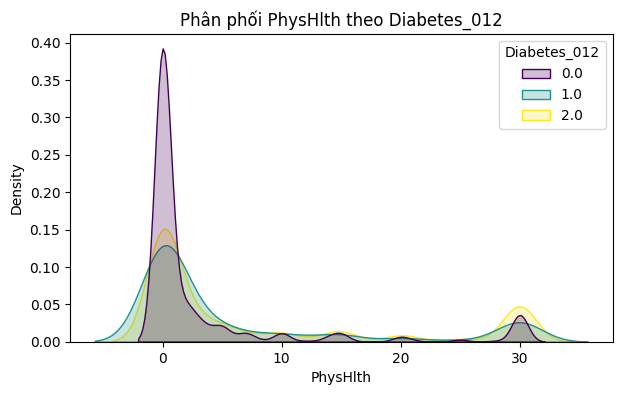

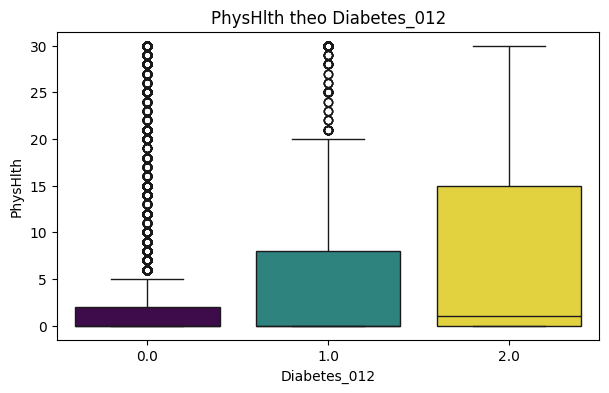

In [10]:
# Biến PhysHlth: Số ngày sức khỏe thể chất kém trong 30 ngày
col = 'PhysHlth'

# 1. Thống kê của biến
print("Thống kê mô tả:")
print(train_df[col].describe().round(2))
print("Độ lệch (skew):", round(train_df[col].skew(), 2))

# Đếm ngoại lai theo quy tắc IQR
q1 = train_df[col].quantile(0.25)
q3 = train_df[col].quantile(0.75)
iqr = q3 - q1
can_duoi = q1 - 1.5 * iqr
can_tren = q3 + 1.5 * iqr
so_ngoai_lai = ((train_df[col] < can_duoi) | (train_df[col] > can_tren)).sum()
print("Cận dưới:", can_duoi, "| Cận trên:", can_tren)
print("Số giá trị ngoại lai:", so_ngoai_lai)
print("Tỷ lệ giá trị bằng 0 (%):", round((train_df[col] == 0).mean() * 100, 1))

# 2. Thống kê của biến theo từng lớp của biến mục tiêu
print("\nThống kê theo Diabetes_012:")
print(train_df.groupby(target)[col].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
plt.figure(figsize=(7, 4))
sns.kdeplot(data=train_df, x=col, hue=target, common_norm=False, fill=True, palette='viridis')
plt.title('Phân phối PhysHlth theo Diabetes_012')
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=train_df, x=target, y=col, hue=target, palette='viridis', legend=False)
plt.title('PhysHlth theo Diabetes_012')
plt.show()

### Nhận xét PhysHlth:
PhysHlth là số ngày sức khỏe thể chất kém trong 30 ngày. Có 63.1 phần trăm người trả lời 0 ngày và 7.6 phần trăm trả lời đủ 30 ngày, tương tự MentHlth nên phân phối cũng dồn về hai đầu và lệch phải với độ lệch 2.21. Trung bình là 4.24 còn trung vị là 0.

Các giá trị bị IQR đánh dấu là ngoại lai đều nằm trong khoảng hợp lệ nên được giữ lại. Nên cân nhắc chia nhóm hoặc biến đổi log ở bước tiền xử lý.

So với biến mục tiêu, trung bình là 3.58 ở lớp 0, 6.35 ở lớp 1 và 7.95 ở lớp 2. Người mắc tiểu đường có số ngày sức khỏe thể chất kém nhiều hơn khoảng hai lần người không mắc, và trung vị của lớp 2 là 1 trong khi hai lớp kia là 0. Biến này liên quan ở mức vừa, rõ hơn MentHlth.

#### Nhóm biến phân loại Nominal

Thống kê của biến:
        Số lượng  Tỷ lệ (%)
HighBP                     
0.0       144851       57.1
1.0       108829       42.9

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
HighBP                           
0.0           134391  1718   8742
1.0            79312  2913  26604

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
HighBP                          
0.0           92.78  1.19   6.04
1.0           72.88  2.68  24.45


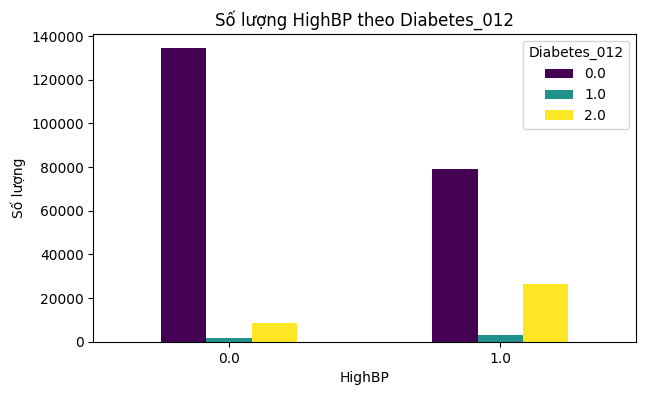

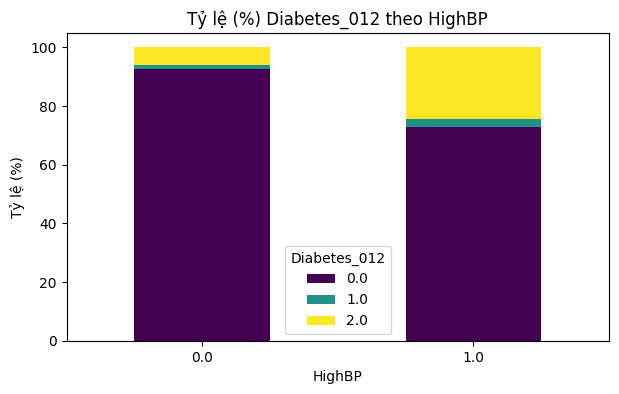

In [11]:
# Biến HighBP: Huyết áp cao
col = 'HighBP'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng HighBP theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo HighBP')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét HighBP:
Có 42.9 phần trăm người được ghi nhận bị huyết áp cao. Trong nhóm huyết áp cao có 24.4 phần trăm mắc tiểu đường, còn nhóm huyết áp bình thường chỉ có 6.0 phần trăm, tức là cao hơn khoảng 4 lần. Tỷ lệ tiền tiểu đường cũng tăng từ 1.2 lên 2.7 phần trăm.

Đây là một trong những biến nhị phân liên quan mạnh nhất với biến mục tiêu.

Thống kê của biến:
          Số lượng  Tỷ lệ (%)
HighChol                     
0.0         146089      57.59
1.0         107591      42.41

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
HighChol                         
0.0           132673  1756  11660
1.0            81030  2875  23686

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
HighChol                        
0.0           90.82  1.20   7.98
1.0           75.31  2.67  22.01


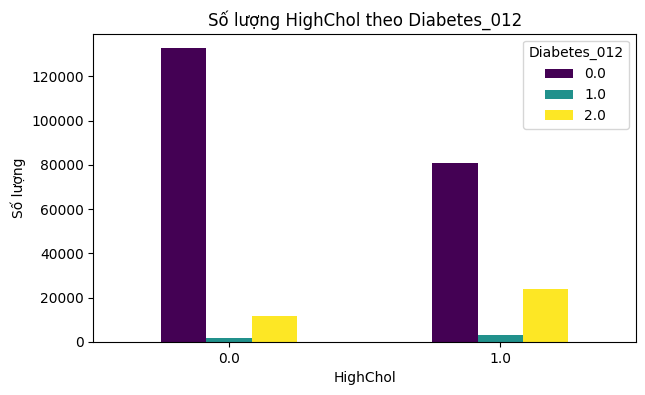

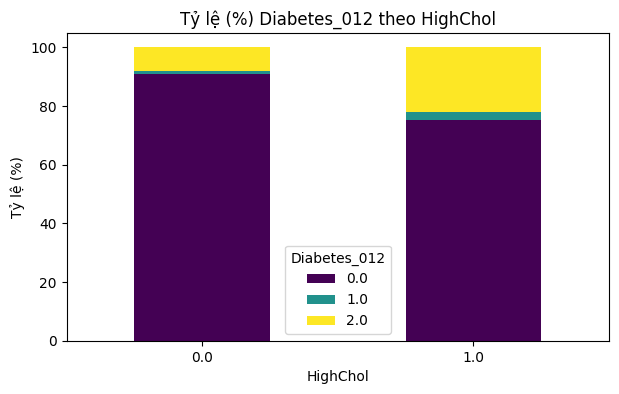

In [12]:
# Biến HighChol: Cholesterol cao
col = 'HighChol'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng HighChol theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo HighChol')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét HighChol:
Có 42.4 phần trăm người có cholesterol cao. Nhóm cholesterol cao có 22.0 phần trăm mắc tiểu đường, nhóm còn lại là 8.0 phần trăm, cao hơn khoảng 2.8 lần. Tỷ lệ tiền tiểu đường tăng từ 1.2 lên 2.7 phần trăm.

Biến này liên quan rõ nhưng yếu hơn HighBP một chút.

Thống kê của biến:
           Số lượng  Tỷ lệ (%)
CholCheck                     
0.0            9470       3.73
1.0          244210      96.27



Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
CholCheck                        
0.0             9167    62    241
1.0           204536  4569  35105

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
CholCheck                       
0.0           96.80  0.65   2.54
1.0           83.75  1.87  14.37


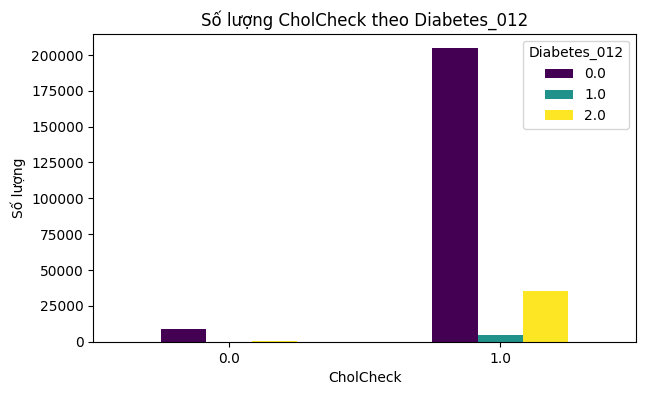

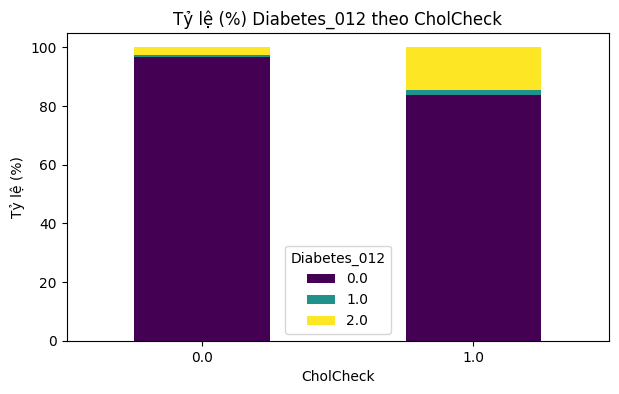

In [13]:
# Biến CholCheck: Kiểm tra cholesterol trong 5 năm
col = 'CholCheck'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng CholCheck theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo CholCheck')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét CholCheck:
Có 96.3 phần trăm người đã kiểm tra cholesterol trong 5 năm qua, còn nhóm chưa kiểm tra chỉ có 9470 người, nên số liệu của nhóm này ít.

Nhóm có kiểm tra mắc tiểu đường 14.4 phần trăm, nhóm không kiểm tra chỉ 2.5 phần trăm. Không thể hiểu là không kiểm tra thì ít bệnh hơn. Nhiều khả năng người chưa từng đi kiểm tra thì cũng chưa được chẩn đoán nên bị bỏ sót, và biến này phản ánh việc tiếp cận y tế nhiều hơn là nguy cơ bệnh.

Thống kê của biến:
        Số lượng  Tỷ lệ (%)
Smoker                     
0.0       141257      55.68
1.0       112423      44.32

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
Smoker                           
0.0           121879  2349  17029
1.0            91824  2282  18317

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
Smoker                          
0.0           86.28  1.66  12.06
1.0           81.68  2.03  16.29


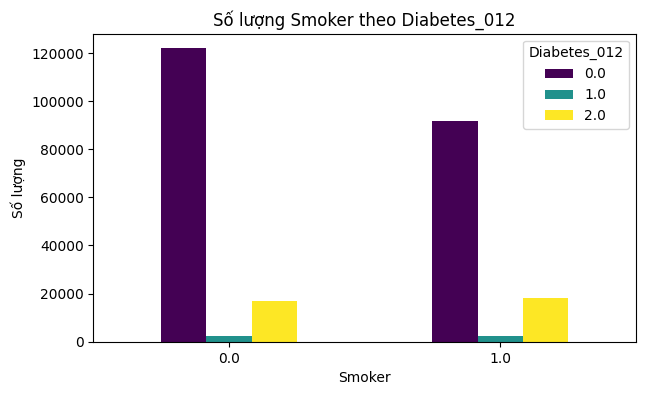

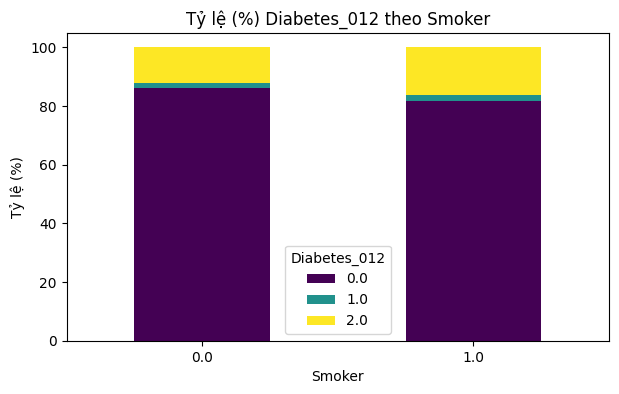

In [14]:
# Biến Smoker: Hút thuốc
col = 'Smoker'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Smoker theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Smoker')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Smoker:
Có 44.3 phần trăm người từng hút ít nhất 100 điếu thuốc. Nhóm hút thuốc mắc tiểu đường 16.3 phần trăm, nhóm không hút là 12.1 phần trăm, chênh khoảng 4 điểm phần trăm.

Có liên quan nhưng yếu, nên biến này ít giúp phân biệt người bệnh.

Thống kê của biến:
        Số lượng  Tỷ lệ (%)
Stroke                     
0.0       243388      95.94
1.0        10292       4.06



Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
Stroke                           
0.0           206944  4366  32078
1.0             6759   265   3268

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
Stroke                          
0.0           85.03  1.79  13.18
1.0           65.67  2.57  31.75


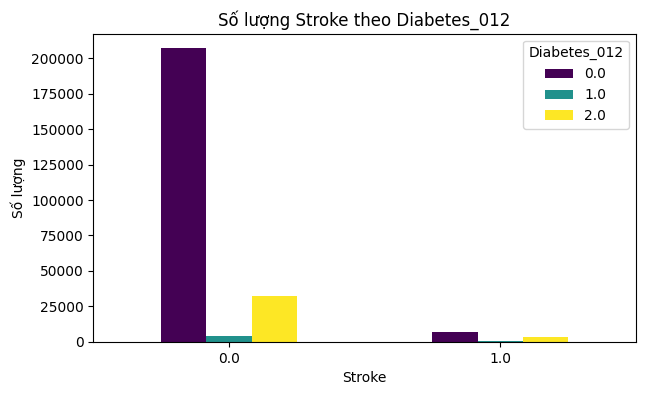

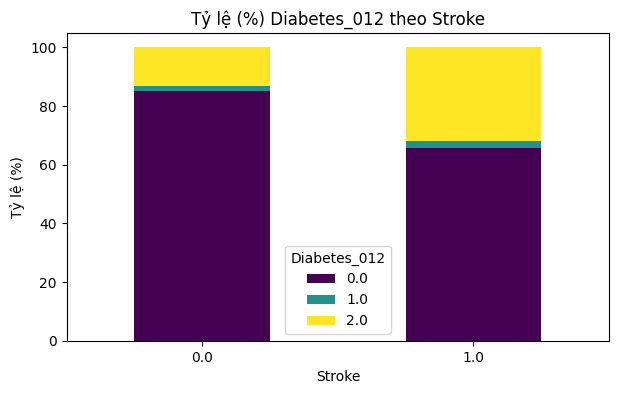

In [15]:
# Biến Stroke: Đột quỵ
col = 'Stroke'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Stroke theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Stroke')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Stroke:
Chỉ có 4.1 phần trăm, tức 10292 người từng bị đột quỵ. Nhóm từng đột quỵ mắc tiểu đường 31.8 phần trăm, trong khi nhóm không bị là 13.2 phần trăm, cao hơn khoảng 2.4 lần.

Khác biệt khá rõ, nhưng nhóm đột quỵ nhỏ nên mỗi biểu đồ cột của nhóm này kém ổn định hơn các biến khác.

Thống kê của biến:
                      Số lượng  Tỷ lệ (%)
HeartDiseaseorAttack                     
0.0                     229787      90.58
1.0                      23893       9.42



Số lượng theo Diabetes_012:
Diabetes_012             0.0   1.0    2.0
HeartDiseaseorAttack                     
0.0                   198352  3967  27468
1.0                    15351   664   7878

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012            0.0   1.0    2.0
HeartDiseaseorAttack                    
0.0                   86.32  1.73  11.95
1.0                   64.25  2.78  32.97


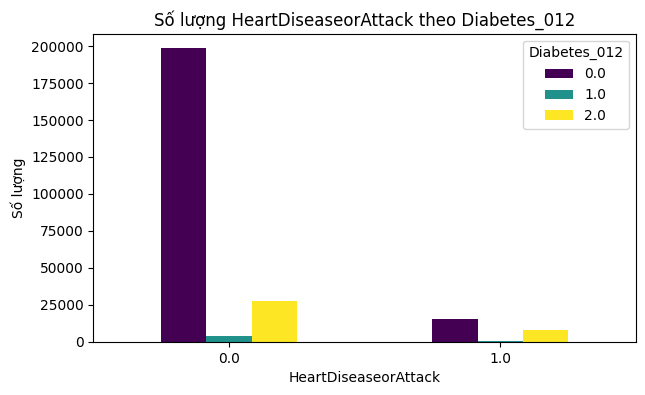

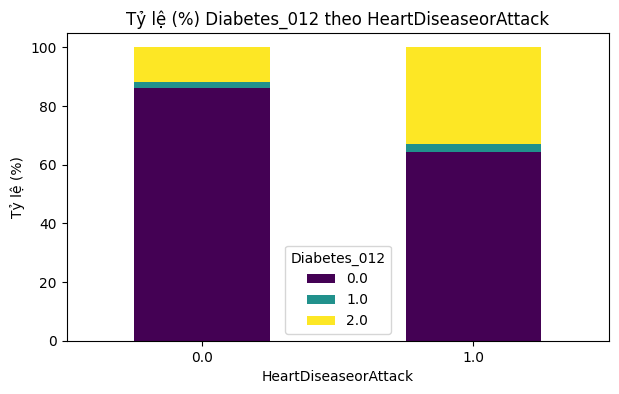

In [16]:
# Biến HeartDiseaseorAttack: Bệnh mạch vành hoặc nhồi máu cơ tim
col = 'HeartDiseaseorAttack'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng HeartDiseaseorAttack theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo HeartDiseaseorAttack')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét HeartDiseaseorAttack:
Có 9.4 phần trăm người từng bị bệnh mạch vành hoặc nhồi máu cơ tim. Nhóm này mắc tiểu đường 33.0 phần trăm, trong khi nhóm còn lại là 12.0 phần trăm, cao hơn khoảng 2.8 lần.

Đây là một trong những biến bệnh lý liên quan rõ với tiểu đường, phù hợp với việc hai bệnh này thường đi cùng nhau.

Thống kê của biến:
              Số lượng  Tỷ lệ (%)
PhysActivity                     
0.0              61760      24.35
1.0             191920      75.65

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
PhysActivity                     
0.0            47212  1489  13059
1.0           166491  3142  22287

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
PhysActivity                    
0.0           76.44  2.41  21.14
1.0           86.75  1.64  11.61


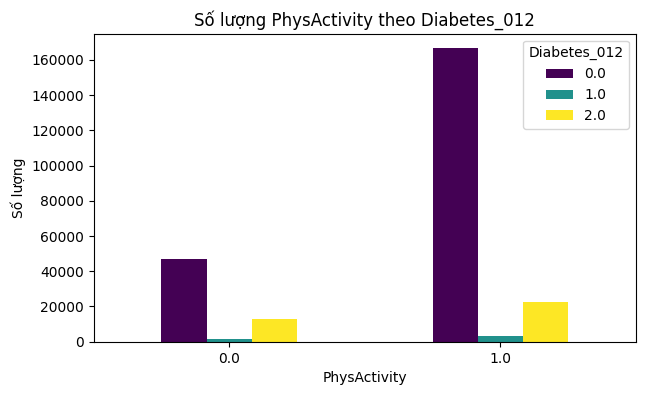

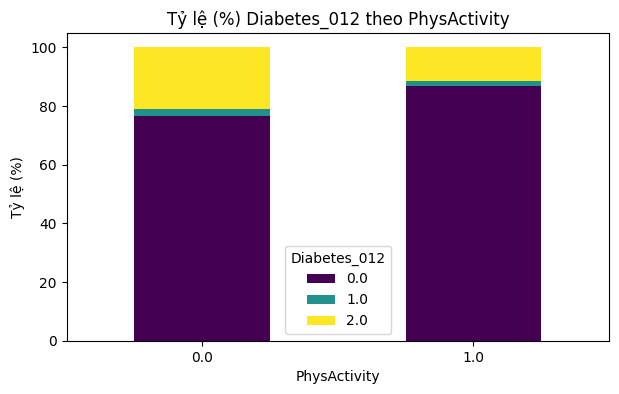

In [17]:
# Biến PhysActivity: Vận động thể chất
col = 'PhysActivity'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng PhysActivity theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo PhysActivity')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét PhysActivity:
Có 75.7 phần trăm người có vận động thể chất. Nhóm có vận động mắc tiểu đường 11.6 phần trăm, nhóm không vận động là 21.1 phần trăm.

Đây là biến hành vi có tác dụng bảo vệ rõ nhất trong dữ liệu. Tuy nhiên chiều ngược lại cũng có thể đúng, vì người đã bệnh có thể vận động ít đi do sức khỏe yếu, nên chưa thể kết luận vận động làm giảm bệnh chỉ từ bảng này.

Thống kê của biến:
        Số lượng  Tỷ lệ (%)
Fruits                     
0.0        92782      36.57
1.0       160898      63.43

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
Fruits                           
0.0            76287  1842  14653
1.0           137416  2789  20693

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
Fruits                          
0.0           82.22  1.99  15.79
1.0           85.41  1.73  12.86


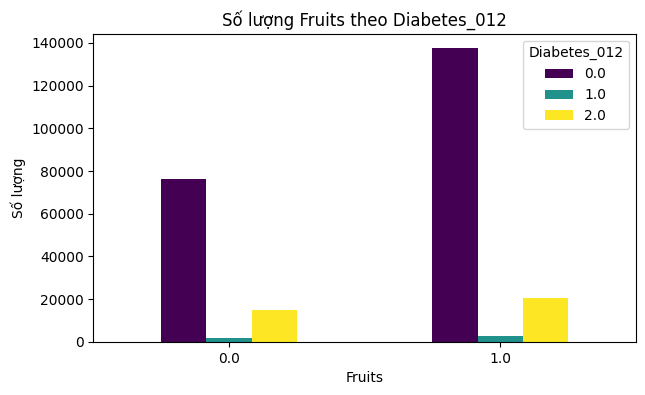

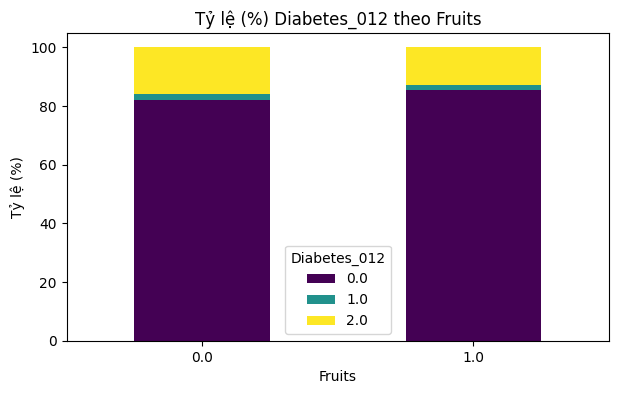

In [18]:
# Biến Fruits: Ăn trái cây
col = 'Fruits'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Fruits theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Fruits')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Fruits:
Có 63.4 phần trăm người ăn trái cây mỗi ngày. Nhóm ăn mắc tiểu đường 12.9 phần trăm, nhóm không ăn là 15.8 phần trăm, chênh khoảng 3 điểm phần trăm.

Khác biệt nhỏ nên biến này liên quan yếu với biến mục tiêu.

Thống kê của biến:
         Số lượng  Tỷ lệ (%)
Veggies                     
0.0         47839      18.86
1.0        205841      81.14

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
Veggies                          
0.0            38159  1070   8610
1.0           175544  3561  26736

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
Veggies                         
0.0           79.77  2.24  18.00
1.0           85.28  1.73  12.99


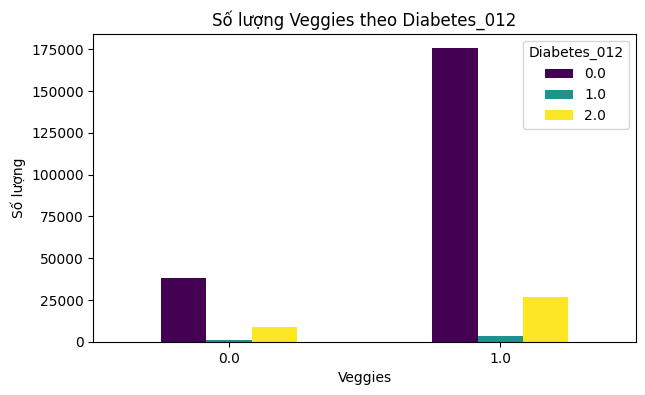

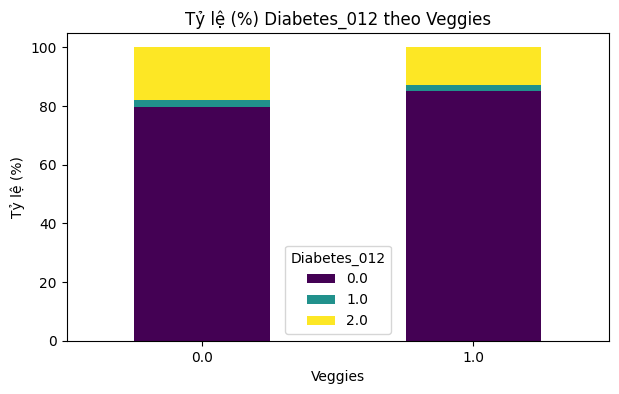

In [19]:
# Biến Veggies: Ăn rau
col = 'Veggies'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Veggies theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Veggies')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Veggies:
Có 81.1 phần trăm người ăn rau mỗi ngày. Nhóm ăn mắc tiểu đường 13.0 phần trăm, nhóm không ăn là 18.0 phần trăm, chênh khoảng 5 điểm phần trăm.

Liên quan ở mức yếu đến vừa, rõ hơn Fruits một chút nhưng vẫn không phải biến mạnh.

Thống kê của biến:
                   Số lượng  Tỷ lệ (%)
HvyAlcoholConsump                     
0.0                  239424      94.38
1.0                   14256       5.62

Số lượng theo Diabetes_012:
Diabetes_012          0.0   1.0    2.0
HvyAlcoholConsump                     
0.0                200487  4423  34514
1.0                 13216   208    832

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012         0.0   1.0    2.0
HvyAlcoholConsump                    
0.0                83.74  1.85  14.42
1.0                92.70  1.46   5.84


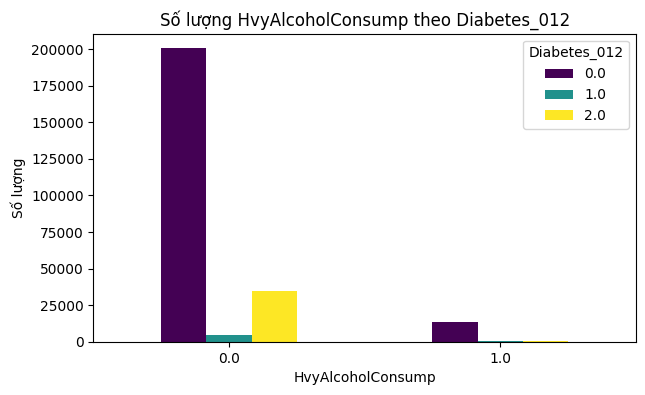

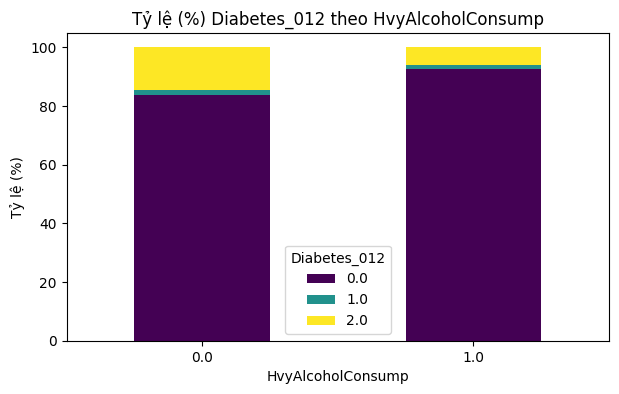

In [20]:
# Biến HvyAlcoholConsump: Uống rượu nhiều
col = 'HvyAlcoholConsump'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng HvyAlcoholConsump theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo HvyAlcoholConsump')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét HvyAlcoholConsump:
Chỉ có 5.6 phần trăm, tức 14256 người uống rượu nhiều. Nhóm này mắc tiểu đường 5.8 phần trăm, thấp hơn nhóm còn lại là 14.4 phần trăm.

Kết quả đi ngược với kỳ vọng thông thường. Không nên kết luận uống rượu giúp tránh bệnh. Có thể người đã mắc bệnh đã bỏ rượu theo lời khuyên của bác sĩ. Cần cẩn thận khi diễn giải biến này.

Thống kê của biến:
               Số lượng  Tỷ lệ (%)
AnyHealthcare                     
0.0               12417       4.89
1.0              241263      95.11

Số lượng theo Diabetes_012:
Diabetes_012      0.0   1.0    2.0
AnyHealthcare                     
0.0             10741   254   1422
1.0            202962  4377  33924

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012     0.0   1.0    2.0
AnyHealthcare                    
0.0            86.50  2.05  11.45
1.0            84.12  1.81  14.06


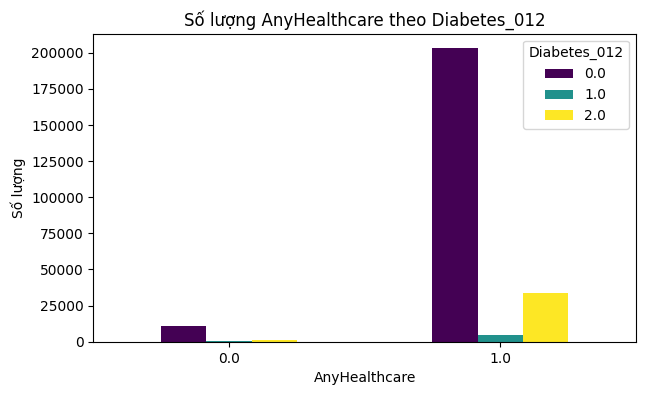

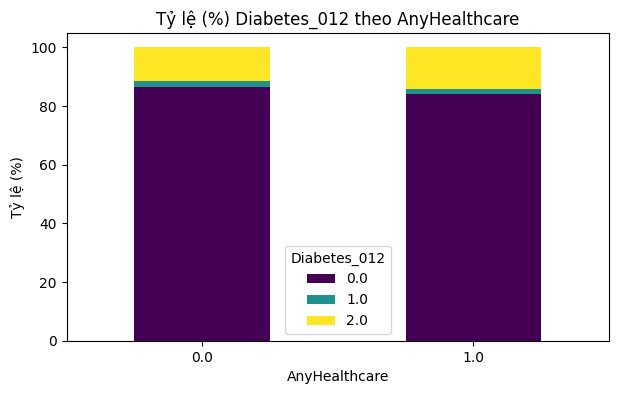

In [21]:
# Biến AnyHealthcare: Có bảo hiểm y tế
col = 'AnyHealthcare'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng AnyHealthcare theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo AnyHealthcare')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét AnyHealthcare:
Có 95.1 phần trăm người có bảo hiểm hoặc dịch vụ y tế, nhóm không có chỉ chiếm 4.9 phần trăm. Nhóm có bảo hiểm mắc tiểu đường 14.1 phần trăm, nhóm không có là 11.5 phần trăm.

Chênh lệch nhỏ và có thể do người có bảo hiểm được khám và phát hiện bệnh nhiều hơn. Biến này liên quan rất yếu.

Thống kê của biến:
             Số lượng  Tỷ lệ (%)
NoDocbcCost                     
0.0            232326      91.58
1.0             21354       8.42

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
NoDocbcCost                      
0.0           196690  4032  31604
1.0            17013   599   3742

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
NoDocbcCost                     
0.0           84.66  1.74  13.60
1.0           79.67  2.81  17.52


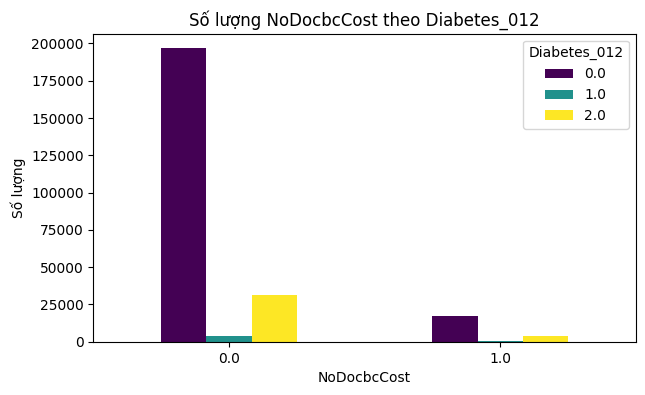

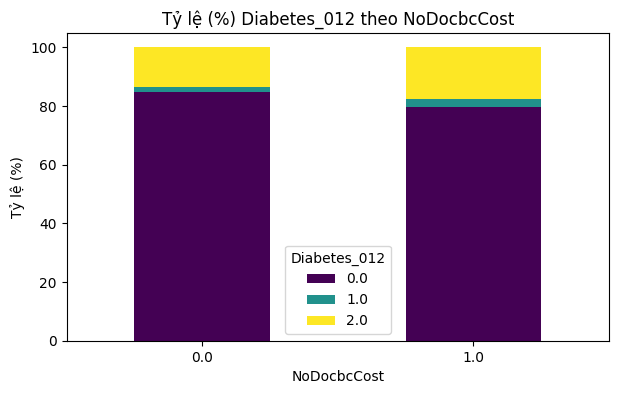

In [22]:
# Biến NoDocbcCost: Không đi khám vì chi phí
col = 'NoDocbcCost'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng NoDocbcCost theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo NoDocbcCost')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét NoDocbcCost:
Có 8.4 phần trăm người từng không đi khám được vì chi phí. Nhóm này mắc tiểu đường 17.5 phần trăm, nhóm còn lại là 13.6 phần trăm. Tỷ lệ tiền tiểu đường cũng cao hơn, 2.8 so với 1.7 phần trăm.

Liên quan yếu, nhưng cho thấy khó khăn tài chính đi cùng với sức khỏe kém hơn.

Thống kê của biến:
          Số lượng  Tỷ lệ (%)
DiffWalk                     
0.0         211005      83.18
1.0          42675      16.82

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
DiffWalk                         
0.0           185434  3346  22225
1.0            28269  1285  13121

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
DiffWalk                        
0.0           87.88  1.59  10.53
1.0           66.24  3.01  30.75


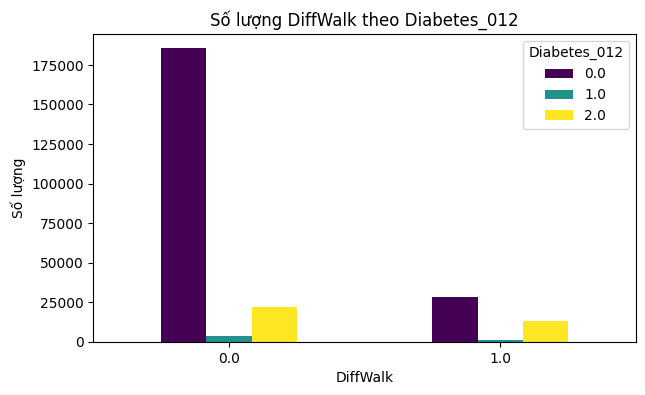

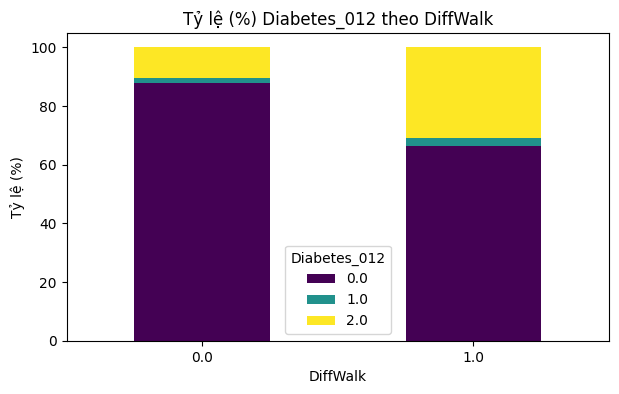

In [23]:
# Biến DiffWalk: Khó đi bộ
col = 'DiffWalk'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng DiffWalk theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo DiffWalk')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét DiffWalk:
Có 16.8 phần trăm người gặp khó khăn nghiêm trọng khi đi bộ hoặc leo cầu thang. Nhóm này mắc tiểu đường 30.7 phần trăm, nhóm còn lại là 10.5 phần trăm, cao hơn khoảng 2.9 lần. Tỷ lệ tiền tiểu đường cũng cao hơn, 3.0 so với 1.6 phần trăm.

Đây là biến liên quan rõ, thuộc nhóm sáu biến mạnh nhất.

Thống kê của biến:
     Số lượng  Tỷ lệ (%)
Sex                     
0.0    141974      55.97
1.0    111706      44.03

Số lượng theo Diabetes_012:
Diabetes_012     0.0   1.0    2.0
Sex                              
0.0           120959  2604  18411
1.0            92744  2027  16935

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
Sex                             
0.0           85.20  1.83  12.97
1.0           83.03  1.81  15.16


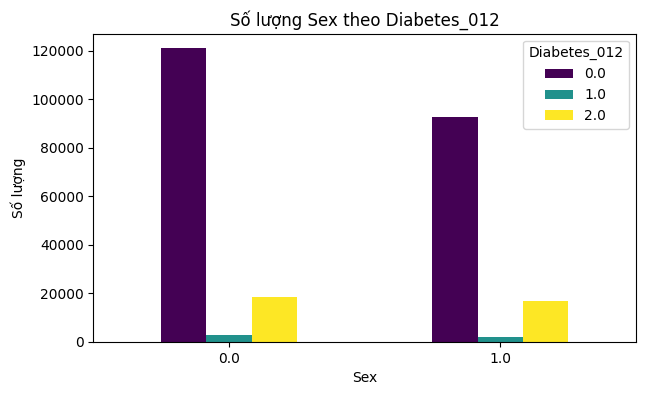

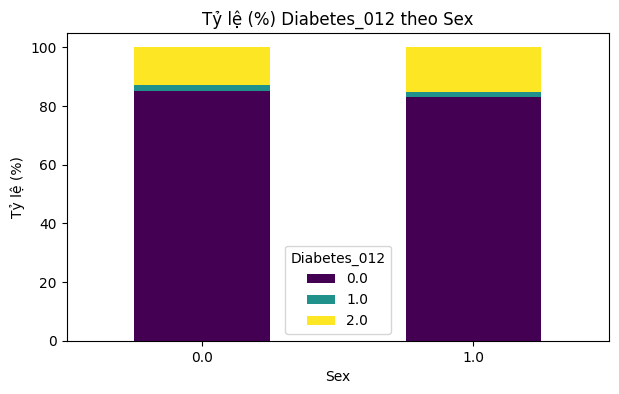

In [24]:
# Biến Sex: Giới tính
col = 'Sex'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Sex theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Sex')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Sex:
Mẫu có 56.0 phần trăm là nữ và 44.0 phần trăm là nam. Nam mắc tiểu đường 15.2 phần trăm, nữ là 13.0 phần trăm.

Khác biệt nhỏ nên giới tính liên quan rất yếu với biến mục tiêu.

#### Nhóm biến phân loại Ordinal

Thống kê của biến:
         Số lượng  Tỷ lệ (%)
GenHlth                     
1.0         45299      17.86
2.0         89084      35.12
3.0         75646      29.82
4.0         31570      12.44
5.0         12081       4.76



Số lượng theo Diabetes_012:
Diabetes_012    0.0   1.0    2.0
GenHlth                         
1.0           43846   313   1140
2.0           81489  1214   6381
3.0           60461  1728  13457
4.0           20755  1025   9790
5.0            7152   351   4578

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
GenHlth                         
1.0           96.79  0.69   2.52
2.0           91.47  1.36   7.16
3.0           79.93  2.28  17.79
4.0           65.74  3.25  31.01
5.0           59.20  2.91  37.89


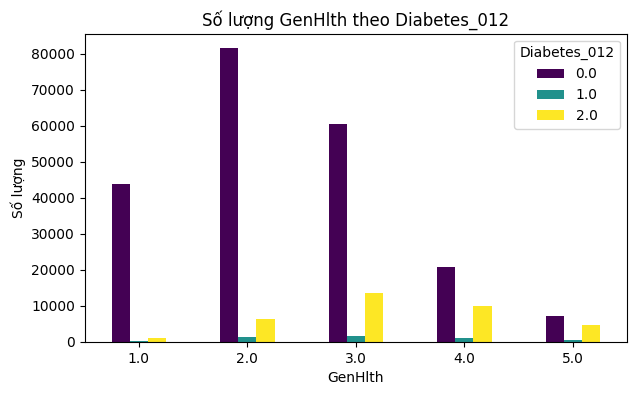

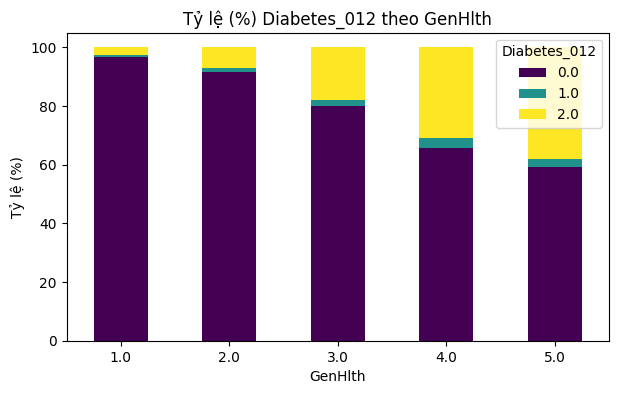

In [25]:
# Biến GenHlth: Sức khỏe tổng quát tự đánh giá
col = 'GenHlth'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng GenHlth theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo GenHlth')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét GenHlth:
Phần lớn người tự đánh giá sức khỏe ở mức rất tốt hoặc tốt, cụ thể mức 2 chiếm 35.1 phần trăm và mức 3 chiếm 29.8 phần trăm. Mức 5 là kém chỉ chiếm 4.8 phần trăm.

Tỷ lệ mắc tiểu đường tăng đều theo từng mức, lần lượt là 2.5, 7.2, 17.8, 31.0 và 37.9 phần trăm từ mức 1 đến mức 5. Người tự thấy sức khỏe kém có tỷ lệ mắc bệnh cao hơn người tự thấy rất tốt khoảng 15 lần.

Đây là biến liên quan mạnh nhất với biến mục tiêu, cả theo hệ số tương quan lẫn Mutual Information ở phần sau. Cần lưu ý đây là đánh giá chủ quan, người đã biết mình bị bệnh có thể sẽ chấm sức khỏe thấp hơn.

Thống kê của biến:
      Số lượng  Tỷ lệ (%)
Age                      
1.0       5700       2.25
2.0       7598       3.00
3.0      11123       4.38
4.0      13823       5.45
5.0      16157       6.37
6.0      19819       7.81
7.0      26314      10.37
8.0      30832      12.15
9.0      33244      13.10
10.0     32194      12.69
11.0     23533       9.28
12.0     15980       6.30
13.0     17363       6.84

Số lượng theo Diabetes_012:
Diabetes_012    0.0  1.0   2.0
Age                           
1.0            5601   21    78
2.0            7404   54   140
3.0           10737   72   314
4.0           13055  142   626
5.0           14943  163  1051
6.0           17765  312  1742
7.0           22808  418  3088
8.0           26019  550  4263
9.0           26809  702  5733
10.0          24939  697  6558
11.0          17790  602  5141
12.0          12132  445  3403
13.0          13701  453  3209

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0


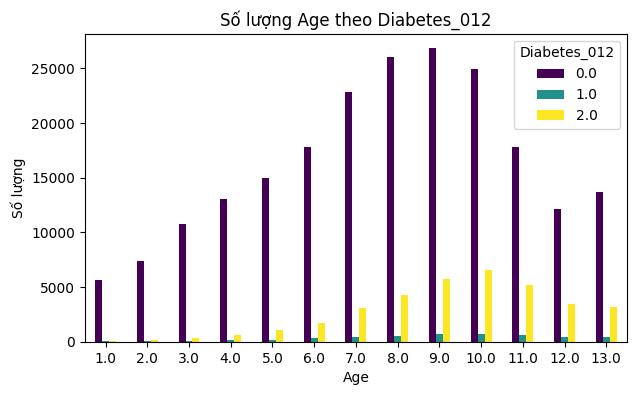

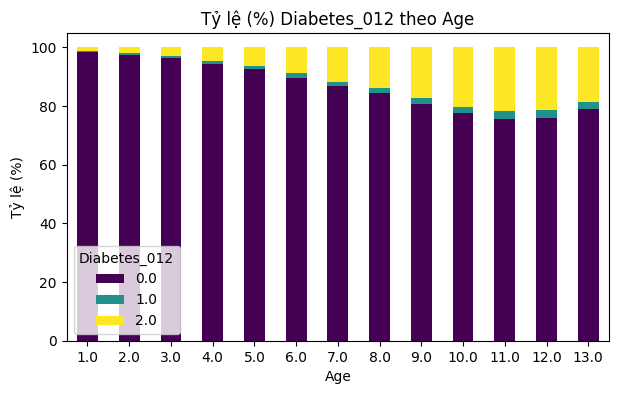

In [26]:
# Biến Age: Nhóm tuổi
col = 'Age'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Age theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Age')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Age:
Số người đông nhất ở các nhóm từ 8 đến 10, tức khoảng từ 55 đến 69 tuổi, mỗi nhóm chiếm khoảng 12 đến 13 phần trăm.

Tỷ lệ mắc tiểu đường tăng rất rõ theo tuổi, từ 1.4 phần trăm ở nhóm 1 lên 21.8 phần trăm ở nhóm 11, tức 70 đến 74 tuổi. Sau đó tỷ lệ giảm nhẹ xuống 21.3 phần trăm ở nhóm 12 và 18.5 phần trăm ở nhóm 13. Sự giảm này có thể do người mắc bệnh nặng khó sống đến tuổi cao hơn, nhưng đây chỉ là suy đoán.

Tuổi là một trong những biến liên quan mạnh nhất. Vì quan hệ không hoàn toàn đi lên, mô hình dựa trên cây sẽ nắm bắt được tốt hơn mô hình tuyến tính.

Thống kê của biến:
           Số lượng  Tỷ lệ (%)
Education                     
1.0             174       0.07
2.0            4043       1.59
3.0            9478       3.74
4.0           62750      24.74
5.0           69910      27.56
6.0          107325      42.31

Số lượng theo Diabetes_012:
Diabetes_012    0.0   1.0    2.0
Education                       
1.0             125     2     47
2.0            2699   161   1183
3.0            6868   314   2296
4.0           50334  1350  11066
5.0           58223  1333  10354
6.0           95454  1471  10400

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
Education                       
1.0           71.84  1.15  27.01
2.0           66.76  3.98  29.26
3.0           72.46  3.31  24.22
4.0           80.21  2.15  17.64
5.0           83.28  1.91  14.81
6.0           88.94  1.37   9.69


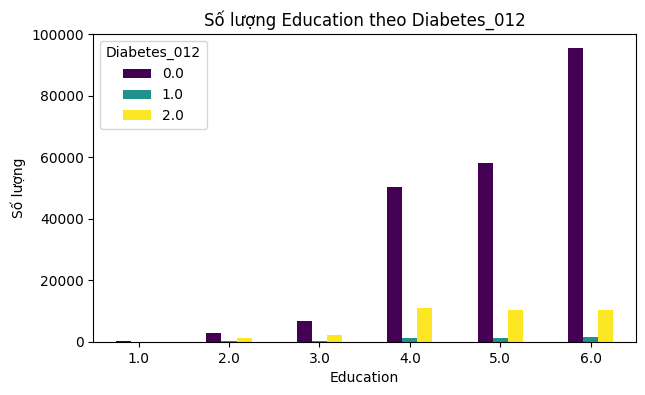

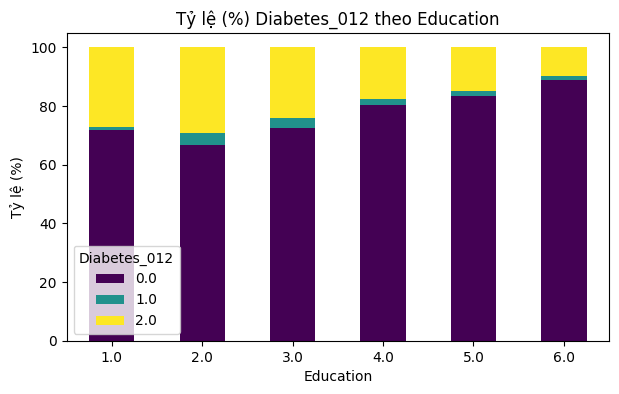

In [27]:
# Biến Education: Trình độ học vấn
col = 'Education'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Education theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Education')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Education:
Nhóm 6 tốt nghiệp đại học chiếm 42.3 phần trăm, trong khi nhóm 1 chỉ có 174 người, rất ít nên tỷ lệ của nhóm này kém tin cậy.

Tỷ lệ mắc tiểu đường giảm khi trình độ học vấn tăng, từ khoảng 27 đến 29 phần trăm ở các nhóm 1 và 2 xuống 9.7 phần trăm ở nhóm 6. Học vấn càng cao thì nguy cơ càng thấp, mức liên quan vừa phải.

Cần lưu ý biến này có tương quan với Income khoảng 0.45, nên hai biến phản ánh phần nào cùng một điều là hoàn cảnh kinh tế xã hội.

Thống kê của biến:
        Số lượng  Tỷ lệ (%)
Income                     
1.0         9811       3.87
2.0        11783       4.64
3.0        15994       6.30
4.0        20135       7.94
5.0        25883      10.20
6.0        36470      14.38
7.0        43219      17.04
8.0        90385      35.63



Số lượng theo Diabetes_012:
Diabetes_012    0.0   1.0   2.0
Income                         
1.0            7114   314  2383
2.0            8341   356  3086
3.0           12005   421  3568
4.0           15622   459  4054
5.0           20792   587  4504
6.0           30431   748  5291
7.0           37219   735  5265
8.0           82179  1011  7195

Tỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:
Diabetes_012    0.0   1.0    2.0
Income                          
1.0           72.51  3.20  24.29
2.0           70.79  3.02  26.19
3.0           75.06  2.63  22.31
4.0           77.59  2.28  20.13
5.0           80.33  2.27  17.40
6.0           83.44  2.05  14.51
7.0           86.12  1.70  12.18
8.0           90.92  1.12   7.96


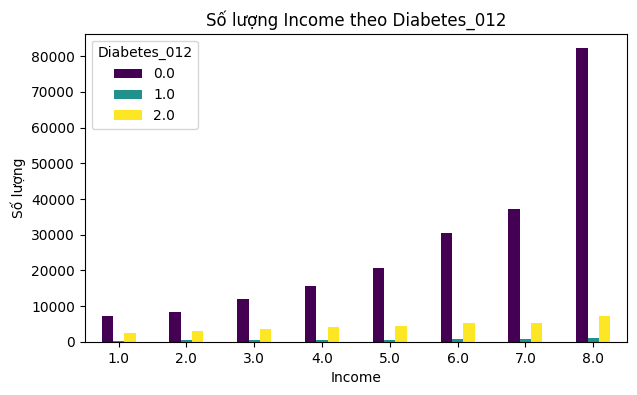

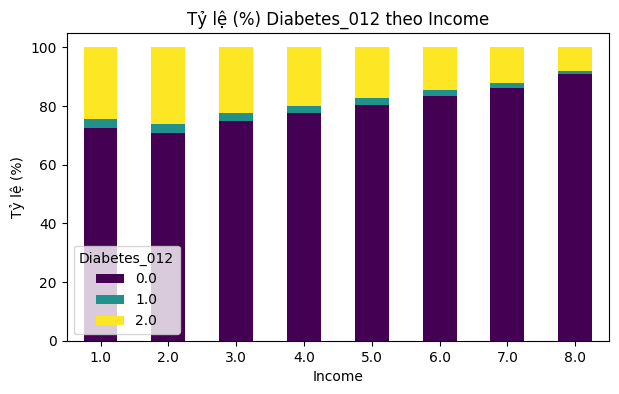

In [28]:
# Biến Income: Thu nhập
col = 'Income'

# 1. Thống kê của biến
thong_ke = pd.DataFrame({
    'Số lượng': train_df[col].value_counts().sort_index(),
    'Tỷ lệ (%)': (train_df[col].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Thống kê của biến:")
print(thong_ke)

# 2. Bảng chéo với biến mục tiêu: số lượng và tỷ lệ phần trăm trong mỗi giá trị của biến
so_luong = pd.crosstab(train_df[col], train_df[target])
ty_le = pd.crosstab(train_df[col], train_df[target], normalize='index') * 100
print("\nSố lượng theo Diabetes_012:")
print(so_luong)
print("\nTỷ lệ (%) theo Diabetes_012, tính trong từng giá trị của biến:")
print(ty_le.round(2))

# 3. Biểu đồ so sánh với biến mục tiêu
so_luong.plot(kind='bar', figsize=(7, 4), colormap='viridis')
plt.title('Số lượng Income theo Diabetes_012')
plt.xlabel(col)
plt.ylabel('Số lượng')
plt.xticks(rotation=0)
plt.show()

ty_le.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='viridis')
plt.title('Tỷ lệ (%) Diabetes_012 theo Income')
plt.xlabel(col)
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=0)
plt.legend(title='Diabetes_012')
plt.show()

### Nhận xét Income:
Nhóm thu nhập cao nhất, mức 8, chiếm đông nhất với 35.6 phần trăm.

Tỷ lệ mắc tiểu đường giảm gần đều khi thu nhập tăng, từ 24.3 và 26.2 phần trăm ở hai mức thấp nhất xuống 8.0 phần trăm ở mức cao nhất. Người thu nhập thấp có tỷ lệ mắc cao hơn khoảng 3 lần. Tỷ lệ tiền tiểu đường cũng giảm từ 3.2 xuống 1.1 phần trăm.

Đây là biến liên quan khá rõ và nằm trong nhóm các biến đứng đầu theo Mutual Information.

### Phân tích đa biến: hai thuộc tính cùng lúc
Cell dưới đây lấy hai thuộc tính bất kỳ và cho biết tỷ lệ phần trăm người mắc tiểu đường, tức Diabetes_012 bằng 2, ở từng tổ hợp giá trị của hai thuộc tính. Đổi hai tên cột ở đầu cell để xem cặp khác.

Age             1.0   2.0   3.0   4.0   5.0   6.0   7.0   8.0   9.0   10.0  \
BMI                                                                          
(11.999, 23.0]   0.7   0.9   1.3   1.6   1.5   2.5   3.6   4.3   4.9   7.2   
(23.0, 26.0]     1.1   0.9   1.6   2.0   2.6   4.3   5.8   6.7   9.8  11.5   
(26.0, 29.0]     2.1   1.8   1.5   2.6   4.8   6.4   9.4  11.5  14.6  18.1   
(29.0, 32.0]     1.7   2.1   3.1   5.0   6.6   9.8  12.8  16.0  20.9  25.1   
(32.0, 98.0]     2.9   4.5   7.1  11.4  16.1  19.5  25.4  29.3  35.4  39.7   

Age             11.0  12.0  13.0  
BMI                               
(11.999, 23.0]   9.0   9.7  10.1  
(23.0, 26.0]    14.0  16.1  16.5  
(26.0, 29.0]    20.4  22.3  21.1  
(29.0, 32.0]    29.1  28.6  26.6  
(32.0, 98.0]    41.0  38.0  36.2  


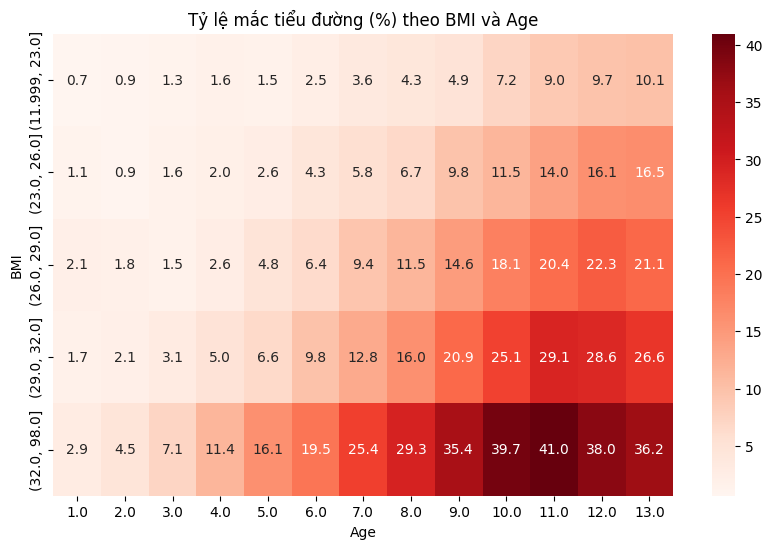

In [29]:
cot_1 = 'BMI'
cot_2 = 'Age'

a = train_df[cot_1]
b = train_df[cot_2]

# Biến có nhiều giá trị khác nhau thì chia thành 5 nhóm có số người gần bằng nhau
if a.nunique() > 15:
    a = pd.qcut(a, q=5, duplicates='drop')
if b.nunique() > 15:
    b = pd.qcut(b, q=5, duplicates='drop')

# Cột 1 là 1 nếu người đó mắc tiểu đường, 0 nếu không. Trung bình của cột này là tỷ lệ mắc bệnh
mac_benh = (train_df[target] == 2).astype(int)

bang = pd.crosstab(a, b, values=mac_benh, aggfunc='mean') * 100
print(bang.round(1))

plt.figure(figsize=(10, 6))
sns.heatmap(bang, annot=True, fmt='.1f', cmap='Reds')
plt.title('Tỷ lệ mắc tiểu đường (%) theo ' + cot_1 + ' và ' + cot_2)
plt.show()

### Nhận xét:
Với cặp BMI và Age, tỷ lệ mắc bệnh thấp nhất là 0.7 phần trăm ở nhóm tuổi 1 có BMI thấp, và cao nhất là 41.0 phần trăm ở nhóm tuổi 11 có BMI trên 32. Ở nhóm tuổi 11, người BMI thấp nhất mắc 9.0 phần trăm còn người BMI cao nhất mắc 41.0 phần trăm. Ở nhóm BMI cao nhất, tuổi tăng từ nhóm 1 lên nhóm 11 làm tỷ lệ tăng từ 2.9 lên 41.0 phần trăm. Hai yếu tố này cộng dồn với nhau, nghĩa là người vừa lớn tuổi vừa thừa cân có nguy cơ cao hơn hẳn người chỉ có một trong hai điều kiện.

Có thể đổi sang các cặp khác như HighBP và HighChol, hoặc GenHlth và Income để kiểm tra những tổ hợp còn lại.

### Tương quan giữa các biến

Tương quan với Diabetes_012:
GenHlth                 0.303
HighBP                  0.272
BMI                     0.224
DiffWalk                0.224
HighChol                0.209
Age                     0.185
HeartDiseaseorAttack    0.180
PhysHlth                0.176
Stroke                  0.107
MentHlth                0.074
CholCheck               0.068
Smoker                  0.063
NoDocbcCost             0.035
Sex                     0.031
AnyHealthcare           0.015
Fruits                 -0.042
HvyAlcoholConsump      -0.058
Veggies                -0.059
PhysActivity           -0.122
Education              -0.131
Income                 -0.171
Name: Diabetes_012, dtype: float64

Các cặp đặc trưng tương quan mạnh nhất:
GenHlth    PhysHlth    0.524
PhysHlth   DiffWalk    0.478
GenHlth    DiffWalk    0.457
Education  Income      0.449
GenHlth    Income      0.370
MentHlth   PhysHlth    0.354
dtype: float64


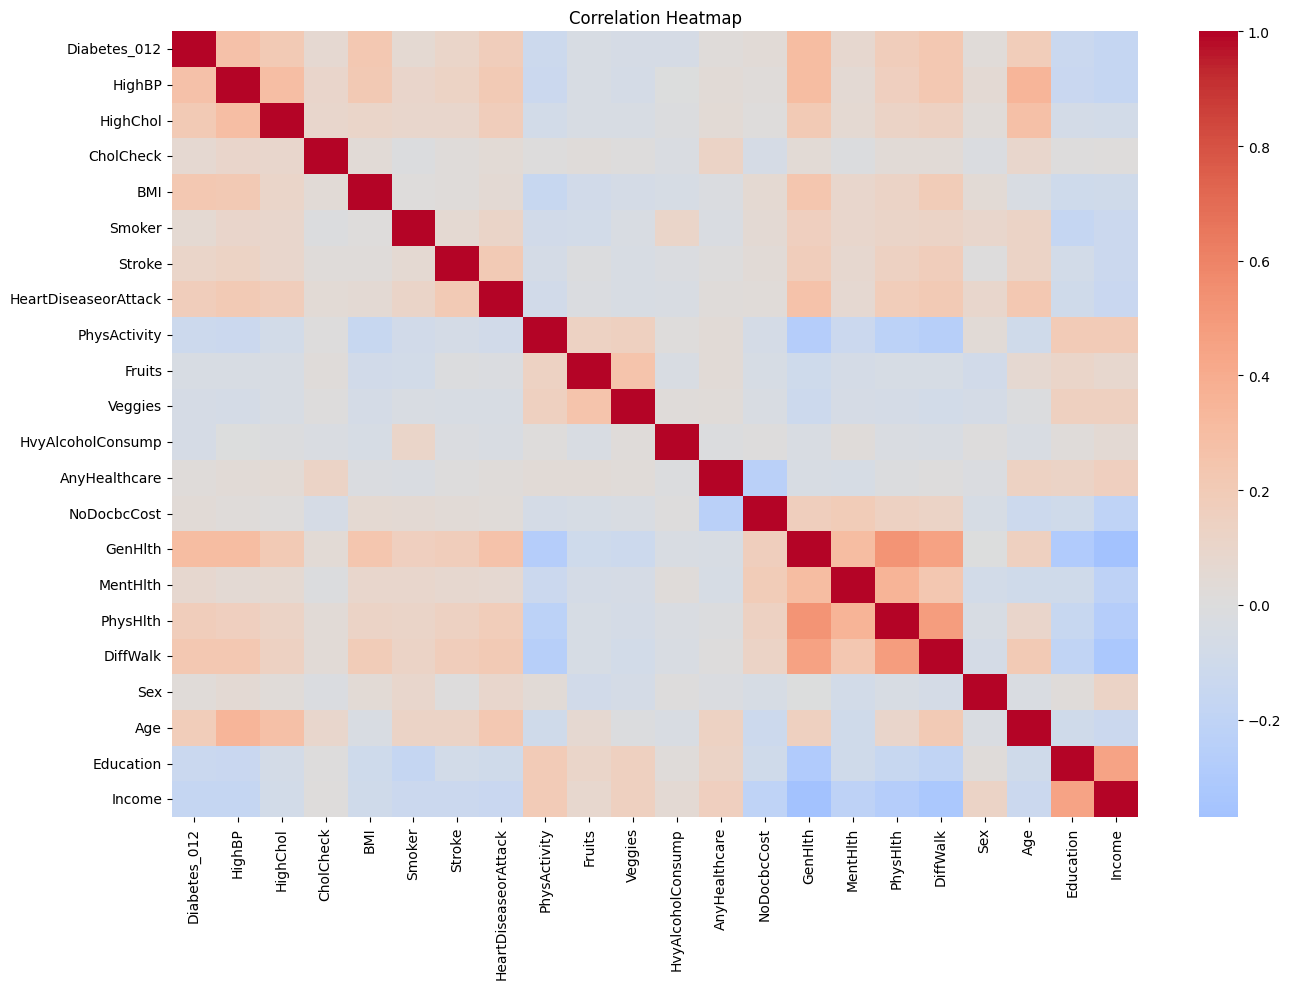

In [30]:
corr = train_df.corr()

# Tương quan của từng đặc trưng với biến mục tiêu, sắp xếp từ cao xuống thấp
print("Tương quan với Diabetes_012:")
print(corr[target].drop(target).sort_values(ascending=False).round(3))

# Các cặp đặc trưng có tương quan mạnh với nhau
cap = corr.drop(index=target, columns=target).abs()
cap = cap.where(np.triu(np.ones(cap.shape), k=1).astype(bool)).stack()
print("\nCác cặp đặc trưng tương quan mạnh nhất:")
print(cap.sort_values(ascending=False).head(6).round(3))

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', annot=False, center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Nhận xét:
Các biến có tương quan dương mạnh nhất với biến mục tiêu là GenHlth 0.303, HighBP 0.272, BMI 0.224, DiffWalk 0.224, HighChol 0.209, Age 0.185, HeartDiseaseorAttack 0.180 và PhysHlth 0.176. Các biến có tương quan âm là Income, Education và PhysActivity, nghĩa là thu nhập, học vấn và vận động càng cao thì nguy cơ càng thấp.

Không có biến nào có tương quan trên 0.31 với biến mục tiêu, nên không có một biến đơn lẻ nào đủ mạnh để dự đoán, mô hình cần kết hợp nhiều biến.

Giữa các đặc trưng với nhau, cặp tương quan mạnh nhất là GenHlth và PhysHlth 0.524, tiếp theo là PhysHlth và DiffWalk 0.478, GenHlth và DiffWalk 0.457, Education và Income 0.449. Không có cặp nào vượt 0.6 nên chưa có hiện tượng đa cộng tuyến nghiêm trọng, chưa cần bỏ biến nào.

Hệ số tương quan Pearson dùng cho cả biến nhị phân và biến thứ bậc chỉ mang tính tham khảo, vì nó đo quan hệ đường thẳng.

### Mức độ quan trọng của đặc trưng theo Mutual Information

,Feature,MI Score
13,GenHlth,0.047067
0,HighBP,0.037435
3,BMI,0.030067
18,Age,0.022087
1,HighChol,0.022049
16,DiffWalk,0.021242
20,Income,0.015080
15,PhysHlth,0.014923
6,HeartDiseaseorAttack,0.013050
19,Education,0.008582


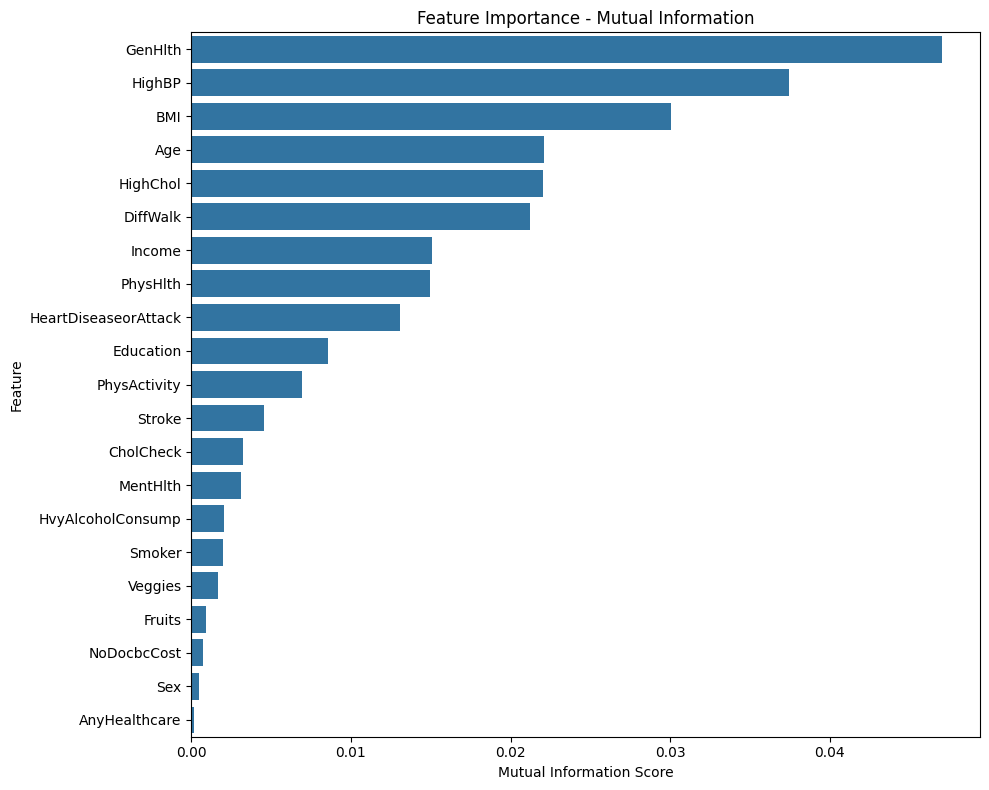

In [31]:
X = train_df.drop(columns=[target])
y = train_df[target]

mi_scores = mutual_info_classif(X, y, discrete_features=True, random_state=42)

mi_df = pd.DataFrame({'Feature': X.columns, 'MI Score': mi_scores})
mi_df = mi_df.sort_values(by='MI Score', ascending=False)
display(mi_df)

plt.figure(figsize=(10, 8))
sns.barplot(data=mi_df, x='MI Score', y='Feature')
plt.title('Feature Importance - Mutual Information')
plt.xlabel('Mutual Information Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Nhận xét:
Thứ tự theo Mutual Information khá giống thứ tự theo tương quan. Sáu biến đứng đầu là GenHlth 0.047, HighBP 0.037, BMI 0.030, Age 0.022, HighChol 0.022 và DiffWalk 0.021. Tiếp theo là Income, PhysHlth và HeartDiseaseorAttack, rồi đến Education và PhysActivity.

Các biến cuối bảng là Fruits, NoDocbcCost, Sex và AnyHealthcare, với điểm gần như bằng 0. Những biến này gần như không giúp đoán được kết quả, có thể cân nhắc bỏ khi chọn đặc trưng. Smoker, Veggies, HvyAlcoholConsump và MentHlth cũng rất thấp, nên chỉ nên giữ nếu thử nghiệm cho thấy có ích.

Việc hai cách đo khác nhau cho cùng một nhóm biến đứng đầu cho thấy kết luận này khá đáng tin.

### Nhận xét tổng kết

Bộ dữ liệu có 253680 dòng và 21 đặc trưng, lấy từ khảo sát sức khỏe của CDC năm 2015. Dữ liệu sạch về mặt thiếu, không có giá trị thiếu nào. Có 23899 dòng trùng nhưng gần như toàn bộ là người khỏe mạnh trả lời giống nhau, nên giữ nguyên.

Vấn đề lớn nhất là biến mục tiêu mất cân bằng. Lớp 0 chiếm 84.24 phần trăm, lớp 2 chiếm 13.93 phần trăm và lớp 1 chỉ chiếm 1.83 phần trăm. Vì vậy cần dùng precision, recall và F1 thay cho accuracy, đồng thời dùng class_weight hoặc lấy mẫu lại, và chia dữ liệu có stratify. Nếu lớp 1 quá khó thì có thể chuyển sang bài toán hai lớp.

Ba biến số BMI, MentHlth và PhysHlth đều lệch phải. MentHlth và PhysHlth có hơn 60 phần trăm giá trị bằng 0 nên nên cân nhắc chia nhóm hoặc biến đổi log.

Các yếu tố liên quan mạnh nhất với tiểu đường là sức khỏe tổng quát tự đánh giá, huyết áp cao, BMI, tuổi, khó đi bộ và cholesterol cao. Thu nhập cao, học vấn cao và có vận động thì đi cùng nguy cơ thấp hơn. Các biến như Sex, AnyHealthcare, NoDocbcCost, Fruits, Smoker và Veggies liên quan rất yếu.

Mọi kết quả ở đây chỉ cho biết các biến đi cùng nhau, chưa chứng minh biến này gây ra bệnh. Ngoài ra có 1834 tổ hợp câu trả lời giống nhau nhưng kết quả khác nhau, nên mô hình sẽ có giới hạn về độ chính xác.

Bước tiếp theo là tiền xử lý, gồm xử lý mất cân bằng, quyết định cách biến đổi các biến số lệch, chọn đặc trưng và chia dữ liệu huấn luyện và kiểm tra.